# 02. Multi-rate baseline на исходных данных

Данный notebook реализует второй этап исследования после EDA исходных данных.  
Его задача — перейти от описания структуры `raw_data/` к воспроизводимому baseline-пайплайну, который объединяет raw logs и KPI во временных окнах.

В отличие от первого notebook, здесь уже формируется рабочий датасет для дальнейшего моделирования. Основной акцент делается не на максимизации качества модели, а на корректности data contract:

- единая сущность наблюдения `run_id = workload / scenario`;
- использование только `STRICT`-пар logs/KPI;
- построение multi-rate окон;
- формирование целевых переменных;
- контроль leakage при train/test split;
- проверка пайплайна с помощью простых baseline-моделей.

Результат notebook должен быть достаточным для следующего этапа — построения основной модели в `03_lcman_lite_raw_data.ipynb`.

## 0. Связь EDA с baseline-контуром

Результаты EDA определяют не только состав входных данных, но и ограничения, которым должен соответствовать baseline-пайплайн. Поэтому в notebook `02` сначала фиксируется data contract, а уже затем выполняется построение признаков и проверка простых моделей.

Ключевым решением является использование `run_id = workload / scenario` как базовой единицы наблюдения. Все операции объединения логов и KPI, построения временных окон и разбиения данных на train/test должны выполняться именно на этом уровне. Это снижает риск некорректного provenance, когда данные разных запусков могут быть ошибочно объединены в одно наблюдение.

Логовая модальность также требует отдельного правила. Файлы `parsed_log/labeled.csv` полезны как источник информации о шаблонах и качестве разметки, однако они не содержат строгой привязки строк к конкретному scenario. Поэтому в baseline-контуре run-level логовые признаки строятся только из `mapred_logs/<scenario>.log`. Это позволяет избежать ситуации, в которой workload-level разметка используется как scenario-level таргет или признак.

Для KPI-модальности основной риск связан с форматом файлов. KPI представлены как whitespace-delimited временные ряды с повторяющимися header rows и внутренними размерностями, такими как `Device:` или `IFACE`. Поэтому в notebook `02` используется отдельный parser, который удаляет повторные заголовки, корректно извлекает `TimeStamp` и сохраняет структуру `host / metric / series`.

Анализ временного разрешения показал, что KPI-данные имеют медианный шаг около одной секунды. Следовательно, они поддерживают короткие окна агрегации. Основным micro-level окном принимается `10s`, а `30s` используется как дополнительный вариант для проверки устойчивости. Окно `5min` не используется как основная target-сетка, поскольку для значительной части run оно приводит к потере временной детализации. В качестве macro-context используется окно `60s`.

Отдельно учитывается дисбаланс целевой разметки. Так как положительные события встречаются редко, качество baseline-моделей не должно оцениваться только через accuracy. Основной метрикой для smoke-baseline является Average Precision / PR-AUC, так как она лучше отражает качество модели при редких положительных классах.

Наконец, EDA показал неполное покрытие logs/KPI и повторяемость workload/failure families. Поэтому baseline-контур должен включать availability-признаки и coverage slices, а также использовать anti-leakage split. В качестве основного подхода применяется разбиение с учётом групп, чтобы близкие сценарии одного workload не оказывались одновременно в train и test.

Таким образом, задача notebook `02` состоит не в подборе сложной модели, а в построении проверяемого baseline-контракта. Модель должна обучаться только после того, как зафиксированы provenance, target policy, правила чтения KPI, схема окон и стратегия защиты от leakage.

## 1. Настройка окружения

В соответствии с результатами EDA фиксируются следующие правила реализации.

Логовые признаки строятся из файлов `mapred_logs/<scenario>.log`, поскольку `parsed_log/labeled.csv` не содержит строгой привязки строк к конкретному scenario.

KPI-файлы читаются как набор временных рядов со структурой `run_id / host / metric / series`. При чтении сохраняется информация о хосте, метрике и способе агрегации внутренних размерностей.

Основной датасет строится только по `STRICT`-запускам, где одновременно доступны raw logs и KPI-измерения. Non-STRICT случаи не используются для обучения, но могут учитываться в диагностике покрытия.

Для передачи в notebook `03` должен формироваться один основной артефакт с готовым baseline-датасетом. Промежуточные таблицы используются внутри notebook и не сохраняются без необходимости.

In [44]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 140)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)

sns.set_theme(style="whitegrid", context="notebook")


# Базовые пути проекта

START_DIR = Path.cwd().resolve()


def find_project_root(start_dir: Path) -> Path:
    """Находит корень проекта по наличию каталога raw_data."""
    for path in [start_dir, *start_dir.parents]:
        if (path / "raw_data").is_dir():
            return path
    return start_dir


PROJECT_ROOT = find_project_root(START_DIR)
RAW_ROOT = PROJECT_ROOT / "raw_data"
OUT_ROOT = PROJECT_ROOT / "outputs" / "raw_multirate"

if not RAW_ROOT.is_dir():
    raise FileNotFoundError(f"Не найден каталог исходных данных: {RAW_ROOT}")

OUT_ROOT.mkdir(parents=True, exist_ok=True)


# Единственный основной артефакт для notebook 03

BASELINE_DATASET_PATH = OUT_ROOT / "multirate_baseline_dataset.csv"


# Основные параметры baseline-пайплайна

EXPECTED_KPI_METRICS = {
    "cpustat",
    "iostat",
    "jvms",
    "memstat",
    "netstat",
    "vmstat",
}

MICRO_WINDOW_SEC = 10
MACRO_WINDOW_SEC = 60

RISK_HORIZON_SEC = 30
WARNING_HORIZON_SEC = 120

SHORT_RISK_FRACTION = 0.25
SHORT_WARNING_FRACTION = 0.60

MAX_LOG_TEXT_CHARS = 2_000
MAX_WINDOWS_PER_RUN_SAFETY = 720

RANDOM_SEED = 42


# Компактная KPI-схема

KPI_SELECTED_COLUMNS = {
    "cpustat": ["%user", "%system", "%iowait", "%idle"],
    "iostat": ["r/s", "w/s", "rkB/s", "wkB/s", "r_await", "w_await", "aqu-sz", "%util"],
    "jvms": ["MapCount", "ReduceCount"],
    "memstat": ["%memused", "kbmemused", "kbavail", "%commit", "%swpused"],
    "netstat": ["rxpck/s", "txpck/s", "rxkB/s", "txkB/s", "%ifutil"],
    "vmstat": ["r", "b", "swpd", "free", "si", "so", "bi", "bo", "us", "sy", "id", "wa"],
}

KPI_DIMENSION_COLUMNS = ["Device:", "IFACE", "DEV", "Filesystem"]

KPI_WINDOW_STATS = ["mean", "last", "std", "delta", "slope"]


context_df = pd.DataFrame(
    [
        {
            "Объект": "Корень проекта",
            "Путь": str(PROJECT_ROOT),
            "Существует": PROJECT_ROOT.exists(),
        },
        {
            "Объект": "Исходные данные",
            "Путь": str(RAW_ROOT),
            "Существует": RAW_ROOT.exists(),
        },
        {
            "Объект": "Выходной каталог",
            "Путь": str(OUT_ROOT),
            "Существует": OUT_ROOT.exists(),
        },
        {
            "Объект": "Основной baseline-артефакт",
            "Путь": str(BASELINE_DATASET_PATH),
            "Существует": BASELINE_DATASET_PATH.exists(),
        },
        {
            "Объект": "EDA notebook",
            "Путь": str(PROJECT_ROOT / "01_eda_raw_data.ipynb"),
            "Существует": (PROJECT_ROOT / "01_eda_raw_data.ipynb").exists(),
        },
    ]
)

context_df

,Объект,Путь,Существует
0,Корень проекта,C:\Main\DGTU\ВКР\Diploma,True
1,Исходные данные,C:\Main\DGTU\ВКР\Diploma\raw_data,True
2,Выходной каталог,C:\Main\DGTU\ВКР\Diploma\outputs\raw_multirate,True
3,Основной baseline-артефакт,C:\Main\DGTU\ВКР\Diploma\outputs\raw_multirate\multirate_baseline_dataset.csv,False
4,EDA notebook,C:\Main\DGTU\ВКР\Diploma\01_eda_raw_data.ipynb,True


## 2. Инвентаризация и политика включения

На этом этапе повторно фиксируется состав доступных запусков, но уже с точки зрения построения baseline-датасета.  
Главный вопрос раздела: какие `run_id` можно использовать в supervised baseline без нарушения provenance.

В соответствии с результатами EDA используется следующая политика:

- в основной датасет включаются только `STRICT`-запуски, где одновременно доступны raw log и KPI-измерения;
- `parsed_log/labeled.csv` не является условием включения, так как не содержит строгой scenario-level привязки;
- non-STRICT запуски сохраняются только для аудита покрытия;
- неожиданные KPI-файлы фиксируются отдельно и не читаются как поддерживаемые метрики.

In [45]:
def safe_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []

    return sorted(
        [p for p in path.iterdir() if p.is_dir() and not p.name.startswith(".")],
        key=lambda p: p.name,
    )


def safe_files(path: Path, pattern="*"):
    if not path.exists() or not path.is_dir():
        return []

    return sorted(
        [p for p in path.glob(pattern) if p.is_file() and not p.name.startswith(".")],
        key=lambda p: p.name,
    )


def classify_scenario(scenario_name: str) -> str:
    name = str(scenario_name).lower()
    return "normal" if name.startswith("normal") else "failure"


def failure_family(scenario_name: str) -> str:
    name = str(scenario_name).lower()

    if name.startswith("normal"):
        return "normal"
    if "cpu" in name:
        return "cpu"
    if "memory" in name or "mem" in name or name == "vm_stress" or "vm_" in name:
        return "memory"
    if "io" in name:
        return "io"
    if "net" in name or "lose_package" in name or "mq" in name:
        return "network"
    if "datanode" in name:
        return "datanode"
    if "namenode" in name:
        return "namenode"
    if "nodemanager" in name:
        return "nodemanager"
    if "resourcemanager" in name:
        return "resourcemanager"
    if "master" in name:
        return "master"
    if "worker" in name:
        return "worker"
    if "late" in name or "slow" in name:
        return "timing"
    if "killed" in name:
        return "killed_other"
    if "suspended" in name:
        return "suspended_other"

    return "other"


def failure_mode(scenario_name: str) -> str:
    name = str(scenario_name).lower()

    if name.startswith("normal"):
        return "normal"
    if "killed" in name:
        return "killed"
    if "suspended" in name:
        return "suspended"
    if "stress" in name:
        return "stress"
    if "delay" in name:
        return "delay"
    if "late" in name:
        return "late_sub"
    if "lose" in name:
        return "packet_loss"

    return "other"

### Сканирование raw_data

In [46]:
def scan_run_inventory(raw_root: Path):
    workload_rows = []
    run_rows = []
    issue_rows = []

    for wdir in safe_dirs(raw_root):
        workload = wdir.name

        parsed_dir = wdir / "parsed_log"
        mapred_dir = wdir / "mapred_logs"
        kpis_dir = wdir / "kpis"

        has_labeled = (parsed_dir / "labeled.csv").exists()
        has_normal = (parsed_dir / "normal.csv").exists()
        has_tasks = (parsed_dir / "tasks.csv").exists()

        mapred_logs = {p.stem: p for p in safe_files(mapred_dir, "*.log")}
        kpi_dirs = {p.name: p for p in safe_dirs(kpis_dir)}

        scenario_names = sorted(set(mapred_logs) | set(kpi_dirs))

        if not has_labeled:
            issue_rows.append(
                {
                    "level": "workload",
                    "workload": workload,
                    "scenario": None,
                    "issue": "missing parsed_log/labeled.csv",
                }
            )

        for scenario in scenario_names:
            kpi_dir = kpi_dirs.get(scenario)
            instruments_dir = kpi_dir / "instruments" if kpi_dir else None
            host_dirs = safe_dirs(instruments_dir) if instruments_dir else []

            metric_names = set()
            instrument_files = 0
            instrument_size_bytes = 0

            for host_dir in host_dirs:
                for file_path in safe_files(host_dir):
                    metric_names.add(file_path.name)
                    instrument_files += 1

                    try:
                        instrument_size_bytes += file_path.stat().st_size
                    except OSError:
                        pass

            has_mapred_log = scenario in mapred_logs
            has_kpi_measurements = instrument_files > 0

            strict_path_pair = has_mapred_log and has_kpi_measurements

            if strict_path_pair:
                pair_status = "STRICT"
            elif has_mapred_log:
                pair_status = "LOG_ONLY"
            elif has_kpi_measurements:
                pair_status = "KPI_ONLY"
            else:
                pair_status = "MISSING_OR_AMBIGUOUS"

            unexpected_metrics = sorted(metric_names - EXPECTED_KPI_METRICS)

            if has_mapred_log and not has_kpi_measurements:
                issue_rows.append(
                    {
                        "level": "scenario",
                        "workload": workload,
                        "scenario": scenario,
                        "issue": "mapred log without KPI measurements",
                    }
                )

            if has_kpi_measurements and not has_mapred_log:
                issue_rows.append(
                    {
                        "level": "scenario",
                        "workload": workload,
                        "scenario": scenario,
                        "issue": "KPI measurements without mapred log",
                    }
                )

            if unexpected_metrics:
                issue_rows.append(
                    {
                        "level": "scenario",
                        "workload": workload,
                        "scenario": scenario,
                        "issue": f"unexpected KPI files: {unexpected_metrics}",
                    }
                )

            run_rows.append(
                {
                    "workload": workload,
                    "scenario": scenario,
                    "run_id": f"{workload}/{scenario}",
                    "scenario_type": classify_scenario(scenario),
                    "failure_family": failure_family(scenario),
                    "failure_mode": failure_mode(scenario),
                    "has_mapred_log": has_mapred_log,
                    "mapred_log_path": str(mapred_logs[scenario]) if has_mapred_log else None,
                    "has_kpi_measurements": has_kpi_measurements,
                    "host_count": len(host_dirs),
                    "metric_count": len(metric_names),
                    "instrument_files": instrument_files,
                    "instrument_size_bytes": instrument_size_bytes,
                    "metrics": ", ".join(sorted(metric_names)),
                    "strict_path_pair": strict_path_pair,
                    "pair_status": pair_status,
                    "parsed_label_available": bool(has_labeled),
                    "parsed_normal_available": bool(has_normal),
                    "parsed_tasks_available": bool(has_tasks),
                }
            )

        workload_rows.append(
            {
                "workload": workload,
                "has_labeled_csv": has_labeled,
                "mapred_scenarios": len(mapred_logs),
                "kpi_scenarios": len(kpi_dirs),
            }
        )

    run_inventory = (
        pd.DataFrame(run_rows)
        .sort_values(["workload", "scenario"])
        .reset_index(drop=True)
    )

    if not run_inventory.empty:
        workload_status = (
            run_inventory
            .groupby(["workload", "pair_status"])
            .size()
            .unstack(fill_value=0)
            .reset_index()
        )

        workload_inventory = pd.DataFrame(workload_rows).merge(
            workload_status,
            on="workload",
            how="left",
        )

        for status in ["STRICT", "LOG_ONLY", "KPI_ONLY", "MISSING_OR_AMBIGUOUS"]:
            if status not in workload_inventory.columns:
                workload_inventory[status] = 0

        workload_inventory = workload_inventory.rename(
            columns={
                "STRICT": "strict_scenarios",
                "LOG_ONLY": "log_only_scenarios",
                "KPI_ONLY": "kpi_only_scenarios",
                "MISSING_OR_AMBIGUOUS": "ambiguous_scenarios",
            }
        )
    else:
        workload_inventory = pd.DataFrame(workload_rows)

    inventory_issues = (
        pd.DataFrame(issue_rows)
        .sort_values(["level", "workload", "scenario", "issue"], na_position="first")
        .reset_index(drop=True)
        if issue_rows
        else pd.DataFrame(columns=["level", "workload", "scenario", "issue"])
    )

    return workload_inventory, run_inventory, inventory_issues


dataset_inventory_df, run_inventory_df, inventory_issues_df = scan_run_inventory(RAW_ROOT)

run_inventory_df["included_primary"] = run_inventory_df["pair_status"].eq("STRICT")
run_inventory_df["exclusion_reason"] = np.where(
    run_inventory_df["included_primary"],
    "included",
    run_inventory_df["pair_status"],
)

pairing_audit_used_df = run_inventory_df[
    [
        "workload",
        "scenario",
        "run_id",
        "scenario_type",
        "failure_family",
        "failure_mode",
        "pair_status",
        "strict_path_pair",
        "has_mapred_log",
        "has_kpi_measurements",
        "parsed_label_available",
        "instrument_files",
        "metrics",
        "included_primary",
        "exclusion_reason",
    ]
].copy()

### Распределение статусов включения

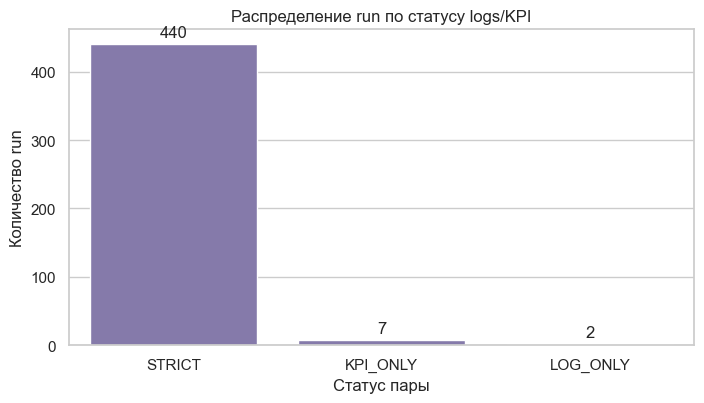

In [47]:
status_counts_df = (
    run_inventory_df
    .groupby("pair_status", as_index=False)
    .agg(runs=("run_id", "nunique"))
    .sort_values("runs", ascending=False)
)

plt.figure(figsize=(7.2, 4.2))

ax = sns.barplot(
    data=status_counts_df,
    x="pair_status",
    y="runs",
    color="#8172B2",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Распределение run по статусу logs/KPI")
plt.xlabel("Статус пары")
plt.ylabel("Количество run")
plt.tight_layout()
plt.show()

### Включённые и исключённые run по workload

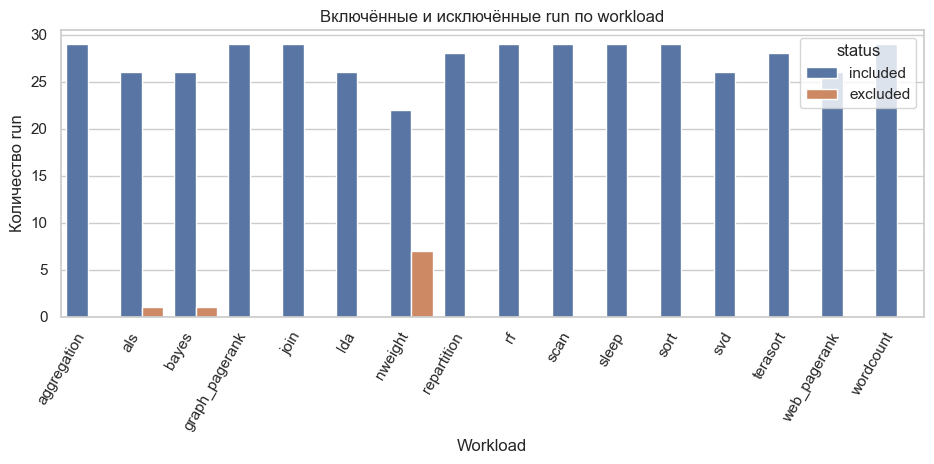

In [48]:
inclusion_by_workload_df = (
    run_inventory_df
    .assign(status=np.where(run_inventory_df["included_primary"], "included", "excluded"))
    .groupby(["workload", "status"], as_index=False)
    .agg(runs=("run_id", "nunique"))
)

plt.figure(figsize=(9.5, 4.8))

sns.barplot(
    data=inclusion_by_workload_df,
    x="workload",
    y="runs",
    hue="status",
)

plt.title("Включённые и исключённые run по workload")
plt.xlabel("Workload")
plt.ylabel("Количество run")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

### Покрытие failure families в primary dataset

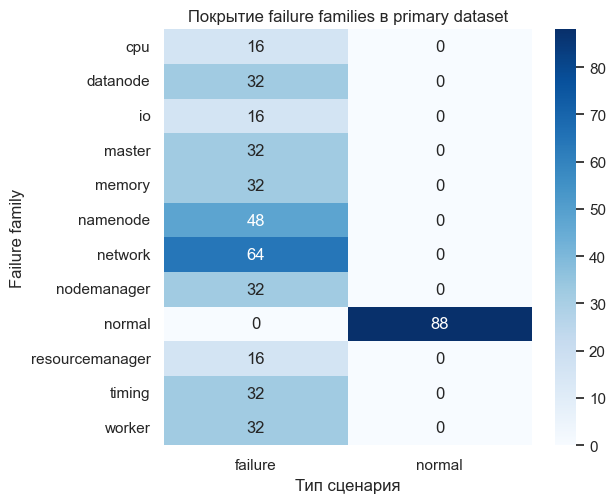

In [49]:
family_matrix = (
    run_inventory_df
    .loc[run_inventory_df["included_primary"]]
    .pivot_table(
        index="failure_family",
        columns="scenario_type",
        values="run_id",
        aggfunc="nunique",
        fill_value=0,
    )
)

plt.figure(figsize=(6.5, 5.2))

sns.heatmap(
    family_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
)

plt.title("Покрытие failure families в primary dataset")
plt.xlabel("Тип сценария")
plt.ylabel("Failure family")
plt.tight_layout()
plt.show()

### Проблемы инвентаризации

In [50]:
inventory_issues_view = inventory_issues_df[
    [
        "level",
        "workload",
        "scenario",
        "issue",
    ]
]

display(inventory_issues_view)

,level,workload,scenario,issue
0,scenario,als,normal6,mapred log without KPI measurements
1,scenario,bayes,normal7,mapred log without KPI measurements
2,scenario,nweight,normal1,KPI measurements without mapred log
3,scenario,nweight,normal2,KPI measurements without mapred log
4,scenario,nweight,normal3,KPI measurements without mapred log
5,scenario,nweight,normal4,KPI measurements without mapred log
6,scenario,nweight,normal5,KPI measurements without mapred log
7,scenario,nweight,normal6,KPI measurements without mapred log
8,scenario,nweight,normal7,KPI measurements without mapred log
9,scenario,web_pagerank,2nd_namenode_killed,unexpected KPI files: ['pgid']


### Выводы по разделу

Инвентаризация подтверждает, что основной baseline-датасет должен строиться только на `STRICT`-запусках, где одновременно доступны raw log и KPI-измерения. Таких запусков обнаружено **440**, тогда как **9** запусков относятся к non-STRICT случаям и исключаются из supervised baseline.

Наличие `parsed_log/labeled.csv` не используется как условие включения. Это важно для workload `nweight`: несмотря на отсутствие workload-level `labeled.csv`, его strict-запуски сохраняются в primary dataset, так как имеют необходимые scenario-level источники — raw logs и KPI.

Non-STRICT случаи не удаляются из результатов анализа, но используются только как аудит покрытия. Отдельно фиксируются неожиданные KPI-файлы, например `pgid`, которые не входят в поддерживаемую KPI-схему и не должны читаться как основные метрики.

Таким образом, политика включения сохраняет строгий provenance на уровне `run_id`, не подменяет scenario-level источники workload-level разметкой и явно отделяет основной supervised dataset от диагностических исключений.

## 3. Загрузка raw logs и признаки уровня run

В этом разделе проверяется возможность использовать `mapred_logs/<scenario>.log` как основной источник логовой модальности на уровне `run_id`.

В отличие от `parsed_log/labeled.csv`, raw log относится к конкретному сценарию, поэтому он подходит для построения run-level и window-level признаков.  
Парсер извлекает только timestamped события, а строки boilerplate учитываются в диагностике качества, но не используются как логовые события.

In [51]:
RAW_LOG_RE = re.compile(
    r"^(?P<date>\d{2}/\d{2}/\d{2})\s+"
    r"(?P<time>\d{2}:\d{2}:\d{2})\s+"
    r"(?P<level>[A-Z]+)\s+"
    r"(?P<component>[^:]+):\s*"
    r"(?P<message>.*)$"
)

KEYWORDS = [
    "error",
    "exception",
    "failed",
    "killed",
    "lost",
    "timeout",
    "suspended",
    "blacklist",
    "retry",
]


def parse_raw_log_line(line: str):
    match = RAW_LOG_RE.match(line.strip())

    if match is None:
        return None

    timestamp = pd.to_datetime(
        f"{match.group('date')} {match.group('time')}",
        format="%y/%m/%d %H:%M:%S",
        utc=True,
        errors="coerce",
    )

    if pd.isna(timestamp):
        return None

    return (
        timestamp,
        match.group("level"),
        match.group("component"),
        match.group("message"),
    )


def normalize_log_message(message: str) -> str:
    text = str(message).lower()

    text = re.sub(r"application_\d+_\d+", "<application_id>", text)
    text = re.sub(r"container_\w+", "<container_id>", text)
    text = re.sub(r"[0-9a-f]{8}-[0-9a-f-]{27,}", "<uuid>", text)
    text = re.sub(r"\b\d{1,3}(?:\.\d{1,3}){3}\b", "<ip>", text)
    text = re.sub(r"hdfs://\S+|file:/\S+|/\S+", "<path>", text)
    text = re.sub(r"\b\d+\b", "<num>", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


def read_raw_log_file(path: Path, workload: str, scenario: str):
    rows = []

    total_lines = 0
    event_lines = 0
    parse_error = None

    try:
        with path.open("r", encoding="utf-8", errors="ignore") as file:
            for line_id, line in enumerate(file, start=1):
                total_lines += 1

                parsed = parse_raw_log_line(line)
                if parsed is None:
                    continue

                timestamp, level, component, message = parsed

                event_lines += 1

                message_norm = normalize_log_message(message)
                message_lower = message.lower()

                rows.append(
                    {
                        "workload": workload,
                        "scenario": scenario,
                        "run_id": f"{workload}/{scenario}",
                        "timestamp": timestamp,
                        "level": level,
                        "component": component,
                        "message": message,
                        "message_norm": message_norm,
                        "keyword_count": sum(
                            int(keyword in message_lower)
                            for keyword in KEYWORDS
                        ),
                        "line_id": line_id,
                    }
                )

    except OSError as exc:
        parse_error = str(exc)

    events = pd.DataFrame(rows)

    if not events.empty:
        ts_min = events["timestamp"].min()
        ts_max = events["timestamp"].max()
    else:
        ts_min = pd.NaT
        ts_max = pd.NaT

    summary = {
        "workload": workload,
        "scenario": scenario,
        "run_id": f"{workload}/{scenario}",
        "raw_log_path": str(path),
        "raw_total_lines": total_lines,
        "raw_event_lines": event_lines,
        "raw_event_line_share": (
            event_lines / total_lines
            if total_lines
            else np.nan
        ),
        "log_ts_min": ts_min,
        "log_ts_max": ts_max,
        "raw_log_duration_sec": (
            (ts_max - ts_min).total_seconds()
            if pd.notna(ts_min) and pd.notna(ts_max)
            else np.nan
        ),
        "raw_log_parse_error": parse_error,
    }

    return events, summary

### Чтение raw logs для included runs

In [52]:
included_inventory_initial = (
    run_inventory_df
    .loc[run_inventory_df["included_primary"]]
    .copy()
)

raw_event_parts = []
raw_summary_rows = []

for record in included_inventory_initial.itertuples(index=False):
    events, summary = read_raw_log_file(
        Path(record.mapred_log_path),
        record.workload,
        record.scenario,
    )

    if not events.empty:
        raw_event_parts.append(events)

    raw_summary_rows.append(summary)

raw_events_df = (
    pd.concat(raw_event_parts, ignore_index=True)
    if raw_event_parts
    else pd.DataFrame()
)

raw_log_summary_df = pd.DataFrame(raw_summary_rows)

raw_log_summary_df = raw_log_summary_df.merge(
    run_inventory_df[
        [
            "run_id",
            "scenario_type",
            "failure_family",
            "failure_mode",
        ]
    ],
    on="run_id",
    how="left",
)

raw_log_summary_df["raw_log_duration_min"] = (
    raw_log_summary_df["raw_log_duration_sec"] / 60
)

### Качество парсинга по семействам отказов

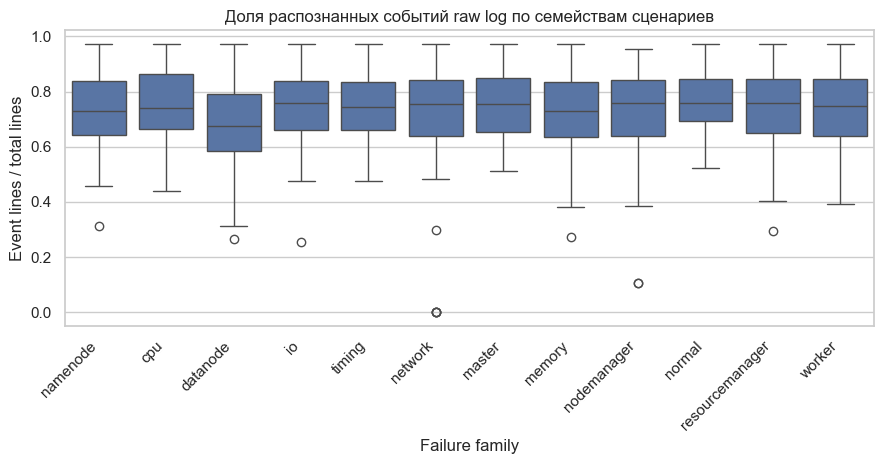

In [53]:
plt.figure(figsize=(9, 4.8))

sns.boxplot(
    data=raw_log_summary_df,
    x="failure_family",
    y="raw_event_line_share",
)

plt.title("Доля распознанных событий raw log по семействам сценариев")
plt.xlabel("Failure family")
plt.ylabel("Event lines / total lines")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Распределение качества парсинга

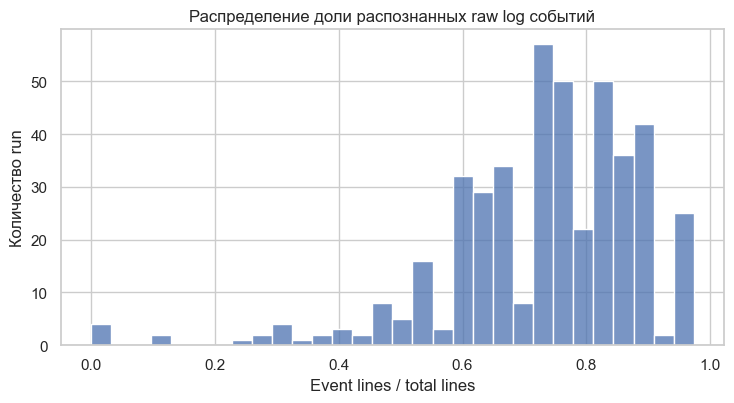

In [54]:
plt.figure(figsize=(7.5, 4.2))

sns.histplot(
    raw_log_summary_df["raw_event_line_share"].dropna(),
    bins=30,
    color="#4C72B0",
)

plt.title("Распределение доли распознанных raw log событий")
plt.xlabel("Event lines / total lines")
plt.ylabel("Количество run")
plt.tight_layout()
plt.show()

### Распределение длительности raw logs

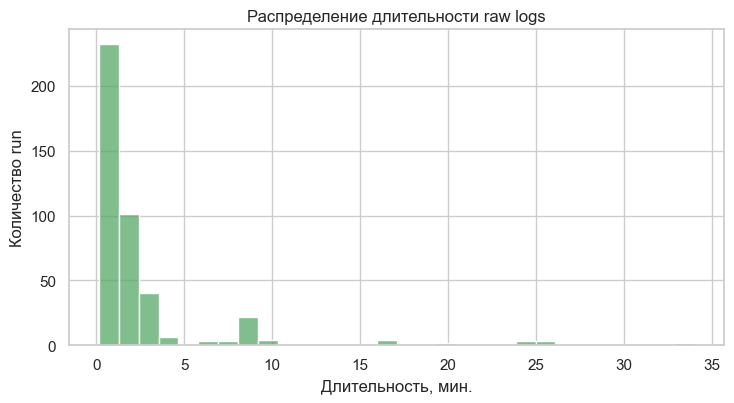

In [55]:
plt.figure(figsize=(7.5, 4.2))

sns.histplot(
    raw_log_summary_df["raw_log_duration_min"].dropna(),
    bins=30,
    color="#55A868",
)

plt.title("Распределение длительности raw logs")
plt.xlabel("Длительность, мин.")
plt.ylabel("Количество run")
plt.tight_layout()
plt.show()

### Выводы по разделу

Raw logs успешно используются как scenario-level источник логовой модальности. В результате парсинга получено **294 366 timestamped log events** из **440 included runs**. Это подтверждает, что `mapred_logs/<scenario>.log` можно использовать для построения логовых признаков на уровне временных окон.

Парсер raw logs работает по следующей логике. Для каждой строки проверяется соответствие регулярному выражению стандартного Spark/YARN-like события: дата, время, уровень логирования, компонент и текст сообщения. Если строка содержит корректный timestamp, она сохраняется как событие с полями `timestamp`, `level`, `component`, `message` и `run_id`. Затем текст сообщения дополнительно нормализуется: идентификаторы приложений, контейнеров, UUID, IP-адреса, пути и числовые значения заменяются на обобщённые токены. Это снижает шум в текстовых признаках и уменьшает риск переобучения на случайные идентификаторы.

Доля распознанных событий отличается между запусками, поскольку часть строк raw log относится к служебному boilerplate и не имеет стандартного timestamped-формата. Такие строки не используются как события, но их наличие учитывается через диагностический показатель `raw_event_line_share`.

Длительность raw logs в большинстве случаев находится в пределах нескольких минут, однако присутствуют более длинные запуски. Это подтверждает необходимость window-level представления: признаки должны строиться не только на уровне всего run, но и внутри micro/macro окон.

Таким образом, дальнейшие логовые признаки в baseline-контуре строятся из `raw_events_df`, а `parsed_log/labeled.csv` не используется как источник scenario-level разметки.

## 4. Парсер KPI, метаданные и компактная схема series

На этом этапе формируется технический контракт для чтения KPI-модальности.  
Полный instrument-каталог имеет большой объём, поэтому в notebook не строится промежуточная long-table по всем значениям KPI.

Вместо этого используется двухэтапный подход:

1. сначала строится file-level index и выполняется lightweight metadata scan;
2. затем на следующих шагах читаются только выбранные KPI-колонки, необходимые для baseline-признаков.

KPI-файлы рассматриваются как набор временных рядов со структурой `run_id / host / metric / series`.  
Внутренние размерности файлов, такие как `Device:` и `IFACE`, агрегируются до host-level представления по явно заданной политике.

In [56]:
import os


def build_kpi_file_index(raw_root: Path):
    rows = []
    issues = []

    for wdir in safe_dirs(raw_root):
        workload = wdir.name

        for scenario_dir in safe_dirs(wdir / "kpis"):
            scenario = scenario_dir.name
            instruments_dir = scenario_dir / "instruments"

            if not instruments_dir.exists():
                issues.append(
                    {
                        "workload": workload,
                        "scenario": scenario,
                        "host": None,
                        "metric": None,
                        "issue": "missing instruments directory",
                    }
                )
                continue

            for host_dir in safe_dirs(instruments_dir):
                host = host_dir.name

                for file_path in safe_files(host_dir):
                    metric = file_path.name
                    expected_metric = metric in EXPECTED_KPI_METRICS

                    try:
                        size_bytes = file_path.stat().st_size
                    except OSError:
                        size_bytes = np.nan

                    if not expected_metric:
                        issues.append(
                            {
                                "workload": workload,
                                "scenario": scenario,
                                "host": host,
                                "metric": metric,
                                "issue": "unexpected metric file",
                            }
                        )

                    rows.append(
                        {
                            "workload": workload,
                            "scenario": scenario,
                            "run_id": f"{workload}/{scenario}",
                            "scenario_type": classify_scenario(scenario),
                            "failure_family": failure_family(scenario),
                            "host": host,
                            "metric": metric,
                            "path": file_path,
                            "rel_path": str(file_path.relative_to(PROJECT_ROOT)),
                            "size_bytes": size_bytes,
                            "expected_metric": expected_metric,
                        }
                    )

    kpi_file_index = pd.DataFrame(rows)
    kpi_file_issues = pd.DataFrame(
        issues,
        columns=["workload", "scenario", "host", "metric", "issue"],
    )

    return kpi_file_index, kpi_file_issues


def extract_timestamp_from_parts(parts):
    if len(parts) < 2:
        return None

    if parts[0] == "HostName" or parts[1] == "TimeStamp":
        return None

    try:
        timestamp = float(parts[1])
    except ValueError:
        return None

    if timestamp <= 0:
        return None

    return timestamp


def read_tail_lines(path: Path, chunk_size=65_536):
    try:
        with path.open("rb") as file:
            file.seek(0, os.SEEK_END)
            end = file.tell()

            if end == 0:
                return []

            offset = max(0, end - chunk_size)
            file.seek(offset)

            data = file.read().decode("utf-8", errors="ignore")

        lines = data.splitlines()

        if offset > 0 and lines:
            lines = lines[1:]

        return lines

    except OSError:
        return []


def kpi_file_metadata(path: Path, max_ts_sample=80):
    header_cols = None
    header_repeats_head = 0
    sample_ts = []
    first_data_line_len = None
    metadata_error = None

    try:
        with path.open("r", encoding="utf-8", errors="ignore") as file:
            for line in file:
                stripped = line.strip()

                if not stripped:
                    continue

                parts = stripped.split()

                if parts and parts[0] == "HostName":
                    header_repeats_head += 1

                    if header_cols is None:
                        header_cols = parts

                    continue

                timestamp = extract_timestamp_from_parts(parts)

                if timestamp is None:
                    continue

                if first_data_line_len is None:
                    first_data_line_len = len(
                        line.encode("utf-8", errors="ignore")
                    )

                sample_ts.append(timestamp)

                if len(sample_ts) >= max_ts_sample:
                    break

    except OSError as exc:
        metadata_error = str(exc)

    last_ts = None

    for line in reversed(read_tail_lines(path)):
        timestamp = extract_timestamp_from_parts(line.strip().split())

        if timestamp is not None:
            last_ts = timestamp
            break

    first_ts = sample_ts[0] if sample_ts else np.nan

    sample_unique = np.array(sorted(set(sample_ts)))

    if len(sample_unique) > 1:
        diffs = np.diff(sample_unique)
        diffs = diffs[diffs > 0]
        median_interval = float(np.median(diffs)) if len(diffs) else np.nan
    else:
        median_interval = np.nan

    dimension_columns = []

    if header_cols:
        dimension_columns = [
            dim
            for dim in KPI_DIMENSION_COLUMNS
            if dim in header_cols
        ]

        value_columns = [
            col
            for col in header_cols
            if col not in {"HostName", "TimeStamp", *dimension_columns}
        ]
    else:
        value_columns = []

    duration_sec = (
        float(last_ts - first_ts)
        if pd.notna(first_ts) and last_ts is not None
        else np.nan
    )

    approx_rows = np.nan

    try:
        if first_data_line_len and first_data_line_len > 0:
            approx_rows = int(path.stat().st_size / first_data_line_len)
    except OSError:
        pass

    return {
        "header_cols": "|".join(header_cols) if header_cols else None,
        "value_columns": "|".join(value_columns),
        "dimension_columns": "|".join(dimension_columns),
        "header_repeats_in_head_sample": header_repeats_head,
        "first_ts": first_ts,
        "last_ts": last_ts,
        "sample_median_interval_sec": median_interval,
        "duration_sec": duration_sec,
        "approx_rows_by_size": approx_rows,
        "metadata_error": metadata_error,
    }

### Посроение KPI-индекса

In [57]:
from tqdm.auto import tqdm

kpi_file_index_df, kpi_file_issues_df = build_kpi_file_index(RAW_ROOT)

metadata_rows = []

for record in tqdm(
    kpi_file_index_df.itertuples(index=False),
    total=len(kpi_file_index_df),
    desc="KPI metadata scan",
):
    metadata_rows.append(kpi_file_metadata(record.path))

kpi_meta_df = pd.concat(
    [
        kpi_file_index_df.reset_index(drop=True),
        pd.DataFrame(metadata_rows),
    ],
    axis=1,
)

kpi_meta_df["first_dt"] = pd.to_datetime(
    kpi_meta_df["first_ts"],
    unit="s",
    utc=True,
    errors="coerce",
)

kpi_meta_df["last_dt"] = pd.to_datetime(
    kpi_meta_df["last_ts"],
    unit="s",
    utc=True,
    errors="coerce",
)

kpi_meta_df["duration_min"] = kpi_meta_df["duration_sec"] / 60
kpi_meta_df["size_mb"] = kpi_meta_df["size_bytes"] / 1024 / 1024

KPI metadata scan:   0%|          | 0/16093 [00:00<?, ?it/s]

### Aгрегаты KPI-метаданных

In [58]:
kpi_run_summary_df = (
    kpi_meta_df
    .loc[kpi_meta_df["expected_metric"]]
    .groupby(["workload", "scenario", "run_id"], as_index=False)
    .agg(
        kpi_hosts=("host", "nunique"),
        kpi_metrics=("metric", "nunique"),
        kpi_files=("metric", "size"),
        kpi_size_mb=("size_mb", "sum"),
        kpi_ts_min=("first_dt", "min"),
        kpi_ts_max=("last_dt", "max"),
        median_file_interval_sec=("sample_median_interval_sec", "median"),
        median_file_duration_min=("duration_min", "median"),
    )
)

kpi_run_summary_df["kpi_duration_min"] = (
    kpi_run_summary_df["kpi_ts_max"] - kpi_run_summary_df["kpi_ts_min"]
).dt.total_seconds() / 60


metric_summary_df = (
    kpi_meta_df
    .groupby("metric", as_index=False)
    .agg(
        files=("metric", "size"),
        runs=("run_id", "nunique"),
        total_size_mb=("size_mb", "sum"),
        median_interval_sec=("sample_median_interval_sec", "median"),
        median_duration_min=("duration_min", "median"),
        metadata_errors=("metadata_error", lambda s: int(s.notna().sum())),
    )
    .sort_values("files", ascending=False)
    .reset_index(drop=True)
)


kpi_selected_schema_df = pd.DataFrame(
    [
        {
            "metric": metric,
            "selected_columns_n": len(columns),
            "selected_value_columns": ", ".join(columns),
            "window_stats": ", ".join(KPI_WINDOW_STATS),
        }
        for metric, columns in KPI_SELECTED_COLUMNS.items()
    ]
)

### Покрытие KPI-файлов по метрикам

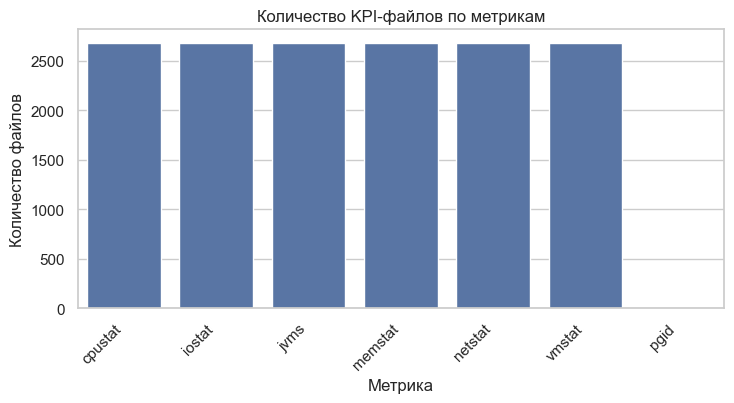

In [59]:
plt.figure(figsize=(7.5, 4.2))

sns.barplot(
    data=metric_summary_df.sort_values("files", ascending=False),
    x="metric",
    y="files",
    color="#4C72B0",
)

plt.title("Количество KPI-файлов по метрикам")
plt.xlabel("Метрика")
plt.ylabel("Количество файлов")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Объём KPI-файлов по метрикам

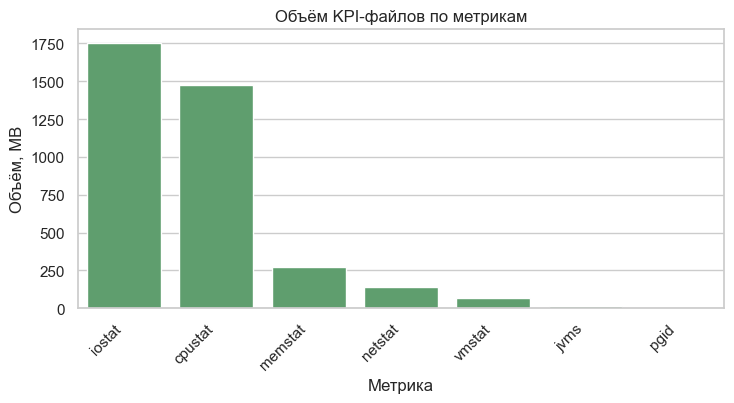

In [60]:
plt.figure(figsize=(7.5, 4.2))

sns.barplot(
    data=metric_summary_df.sort_values("total_size_mb", ascending=False),
    x="metric",
    y="total_size_mb",
    color="#55A868",
)

plt.title("Объём KPI-файлов по метрикам")
plt.xlabel("Метрика")
plt.ylabel("Объём, MB")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Длительность KPI-файлов

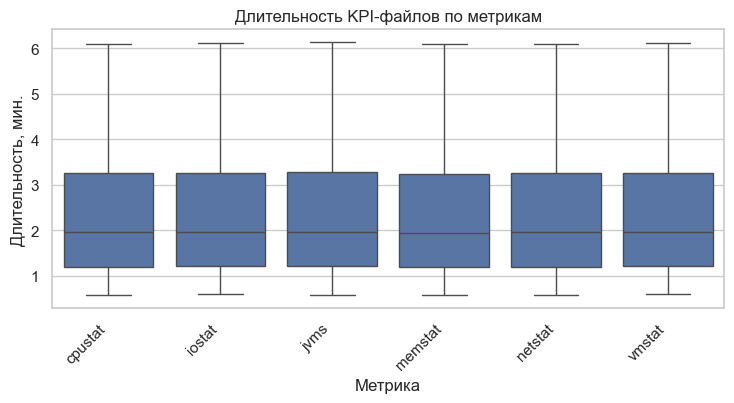

In [61]:
plt.figure(figsize=(7.5, 4.2))

sns.boxplot(
    data=kpi_meta_df.loc[kpi_meta_df["expected_metric"]],
    x="metric",
    y="duration_min",
    showfliers=False,
)

plt.title("Длительность KPI-файлов по метрикам")
plt.xlabel("Метрика")
plt.ylabel("Длительность, мин.")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Компактная KPI-схема

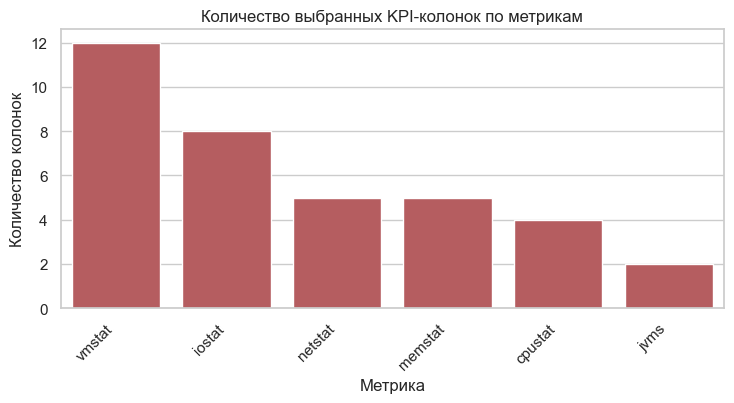

In [62]:
plt.figure(figsize=(7.5, 4.2))

sns.barplot(
    data=kpi_selected_schema_df.sort_values("selected_columns_n", ascending=False),
    x="metric",
    y="selected_columns_n",
    color="#C44E52",
)

plt.title("Количество выбранных KPI-колонок по метрикам")
plt.xlabel("Метрика")
plt.ylabel("Количество колонок")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Логика чтения KPI values

После metadata scan используется тот же набор KPI-файлов, но читаются уже только выбранные колонки compact-схемы. Полная long-table по всем KPI values не строится.

Парсер работает пофайлово: сначала находит header, проверяет наличие `HostName` и `TimeStamp`, выбирает только поддерживаемые значения для конкретной метрики, удаляет повторные header rows и приводит timestamp/value-поля к числовому типу.

Если внутри одного timestamp есть несколько строк из-за размерностей `Device:`, `IFACE`, CPU-slot или аналогичных структур, они агрегируются до host-level представления через `mean_dim` и `max_dim`. Затем эти временные ряды будут агрегироваться уже внутри micro-window статистиками `mean`, `last`, `std`, `delta` и `slope`.

In [63]:
def read_first_header(path: Path):
    try:
        with path.open("r", encoding="utf-8", errors="ignore") as file:
            for line in file:
                stripped = line.strip()

                if stripped:
                    return stripped.split()

    except OSError:
        return []

    return []


def safe_token(value) -> str:
    token = str(value).strip().lower()
    token = re.sub(r"[^a-z0-9]+", "_", token)
    token = token.strip("_")
    return token or "na"


def read_kpi_selected_df(path: Path, metric: str):
    selected_cols = KPI_SELECTED_COLUMNS.get(metric, [])

    if not selected_cols:
        return pd.DataFrame(), "metric_not_selected"

    header = read_first_header(path)

    if "HostName" not in header or "TimeStamp" not in header:
        return pd.DataFrame(), "missing HostName/TimeStamp header"

    available_values = [
        column
        for column in selected_cols
        if column in header
    ]

    if not available_values:
        return pd.DataFrame(), "no selected value columns in file"

    usecols = (
        ["HostName", "TimeStamp"]
        + [column for column in KPI_DIMENSION_COLUMNS if column in header]
        + available_values
    )

    try:
        df = pd.read_csv(
            path,
            sep=r"\s+",
            usecols=usecols,
        )

    except Exception as exc:
        return pd.DataFrame(), f"read_csv failed: {exc}"

    if "TimeStamp" not in df.columns:
        return pd.DataFrame(), "missing TimeStamp after read"

    df = df.loc[df["TimeStamp"].astype(str) != "TimeStamp"].copy()
    df["TimeStamp"] = pd.to_numeric(df["TimeStamp"], errors="coerce")
    df = df.loc[df["TimeStamp"].notna()].copy()

    for column in available_values:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    value_cols = [
        column
        for column in available_values
        if column in df.columns and df[column].notna().any()
    ]

    if not value_cols:
        return pd.DataFrame(), "no numeric selected values"

    return df[["TimeStamp"] + value_cols], None


def kpi_feature_frame_for_file(
    record,
    run_start_epoch: float,
    n_windows: int,
    micro_sec: int,
):
    df, issue = read_kpi_selected_df(
        Path(record.path),
        record.metric,
    )

    if issue:
        return (
            None,
            None,
            {
                "run_id": record.run_id,
                "host": record.host,
                "metric": record.metric,
                "path": str(record.path),
                "issue": issue,
            },
        )

    value_cols = [
        column
        for column in df.columns
        if column != "TimeStamp"
    ]

    if not value_cols:
        return (
            None,
            None,
            {
                "run_id": record.run_id,
                "host": record.host,
                "metric": record.metric,
                "path": str(record.path),
                "issue": "empty selected values",
            },
        )

    # Повторяющиеся timestamp-строки кодируют внутренние размерности
    # CPU/device/interface. Они агрегируются до host-level mean/max.
    per_ts = (
        df
        .groupby("TimeStamp", as_index=True)[value_cols]
        .agg(["mean", "max"])
        .sort_index()
    )

    per_ts.columns = [
        f"{column}__{aggregation}_dim"
        for column, aggregation in per_ts.columns
    ]

    ts_numeric = per_ts.index.to_numpy(dtype=float)

    window_index = np.floor(
        (ts_numeric - run_start_epoch) / micro_sec
    ).astype(int)

    valid_mask = (
        (window_index >= 0)
        & (window_index < n_windows)
    )

    if not valid_mask.any():
        return (
            None,
            None,
            {
                "run_id": record.run_id,
                "host": record.host,
                "metric": record.metric,
                "path": str(record.path),
                "issue": "timestamps outside run span",
            },
        )

    per_ts = per_ts.iloc[np.where(valid_mask)[0]].copy()
    per_ts["window_index"] = window_index[valid_mask]
    per_ts["ts_numeric"] = ts_numeric[valid_mask]

    recency = (
        per_ts
        .groupby("window_index", as_index=False)["ts_numeric"]
        .max()
        .rename(columns={"ts_numeric": "last_kpi_ts_epoch"})
    )

    out_parts = []
    schema_rows = []

    feature_columns = [
        column
        for column in per_ts.columns
        if column not in {"window_index", "ts_numeric"}
    ]

    for raw_feature_name in feature_columns:
        raw_series, dim_aggregation = raw_feature_name.rsplit("__", 1)

        feature_base = (
            f"kpi_{safe_token(record.host)}"
            f"__{safe_token(record.metric)}"
            f"__{safe_token(raw_series)}"
            f"__{safe_token(dim_aggregation)}"
        )

        tmp = (
            per_ts[
                [
                    "window_index",
                    "ts_numeric",
                    raw_feature_name,
                ]
            ]
            .dropna()
            .sort_values(["window_index", "ts_numeric"])
        )

        if tmp.empty:
            continue

        grouped = tmp.groupby("window_index")

        first = grouped[raw_feature_name].first()
        last = grouped[raw_feature_name].last()
        mean = grouped[raw_feature_name].mean()
        std = grouped[raw_feature_name].std(ddof=0).fillna(0.0)
        delta = last - first

        span = (
            grouped["ts_numeric"].max()
            - grouped["ts_numeric"].min()
        ).replace(0, np.nan)

        slope = (
            delta / span
        ).replace([np.inf, -np.inf], np.nan).fillna(0.0)

        feature_part = pd.DataFrame(
            {
                f"{feature_base}__mean": mean,
                f"{feature_base}__last": last,
                f"{feature_base}__std": std,
                f"{feature_base}__delta": delta,
                f"{feature_base}__slope": slope,
            }
        )

        out_parts.append(feature_part)

        schema_rows.append(
            {
                "feature_base": feature_base,
                "host": record.host,
                "metric": record.metric,
                "raw_series": raw_series,
                "dimension_aggregation": dim_aggregation,
                "stats": KPI_WINDOW_STATS,
                "source_path_example": (
                    str(record.rel_path)
                    if hasattr(record, "rel_path")
                    else str(record.path)
                ),
            }
        )

    if not out_parts:
        return (
            None,
            recency,
            {
                "run_id": record.run_id,
                "host": record.host,
                "metric": record.metric,
                "path": str(record.path),
                "issue": "no window features created",
            },
        )

    feature_frame = pd.concat(out_parts, axis=1)
    feature_frame.index.name = "window_index"
    feature_frame = feature_frame.reset_index()

    return feature_frame, recency, schema_rows

### Выводы по разделу

Metadata scan охватывает **16 093 KPI-файла**, из которых **16 092** относятся к ожидаемым метрикам. Единственный нестандартный файл связан с метрикой `pgid`; он фиксируется в аудите, но не входит в поддерживаемую KPI-схему.

KPI parser работает в два этапа. Сначала для каждого файла строится metadata-профиль: извлекаются заголовки, первые и последние timestamp, приблизительная длительность файла, медианный интервал дискретизации и возможные ошибки чтения. На этом этапе полный value-level датасет не строится. Затем в baseline-пайплайне читаются только заранее выбранные KPI-колонки, необходимые для построения признаков.

Основные KPI-метрики имеют одинаковое покрытие по числу файлов и запусков. При этом объём данных распределён неравномерно: наибольший вклад дают метрики с более широкими или более частыми системными измерениями, прежде всего `iostat` и `cpustat`.

Медианный интервал дискретизации ожидаемых KPI-файлов составляет около **1 секунды**, что подтверждает возможность построения micro-level окон. Длительность KPI-файлов в основном сопоставима между метриками, поэтому дальнейшая агрегация может выполняться единой window-схемой.

Для baseline используется компактная KPI-схема: из каждой метрики выбирается ограниченный набор интерпретируемых колонок, а внутренние размерности `Device:`, `IFACE` и аналогичные повторяющиеся строки агрегируются до host-level представления. Полная long-table по всем KPI values на этом этапе не строится, чтобы не создавать тяжёлый промежуточный датасет.

Таким образом, KPI-модальность подготавливается как набор временных рядов, которые далее агрегируются непосредственно в micro/macro windows с явной политикой чтения, агрегации и именования признаков.

## 5. Границы run, выбор micro-window и политика target

На этом этапе определяются временные границы каждого `run_id` и формируется политика построения target-разметки.

Границы run задаются как объединение временного покрытия raw logs и KPI-файлов. Такой подход позволяет не отдавать предпочтение одной модальности и использовать максимально полный временной интервал запуска.

Для failure-сценариев дополнительно определяется `event_anchor` — приближённая точка отказа. Если в raw log найдено устойчивое событие с ключевыми словами отказа или высоким уровнем логирования, оно используется как explicit anchor. Если такого события нет, применяется `run_end_proxy`. Этот proxy не трактуется как истинный момент отказа, а сохраняется как отдельная политика разметки.

Для normal-сценариев `event_anchor` не задаётся, а целевые признаки равны нулю.

In [64]:
run_spans_df = (
    run_inventory_df
    .merge(
        raw_log_summary_df[
            [
                "run_id",
                "log_ts_min",
                "log_ts_max",
                "raw_event_lines",
                "raw_event_line_share",
                "raw_log_duration_sec",
            ]
        ],
        on="run_id",
        how="left",
    )
    .merge(
        kpi_run_summary_df[
            [
                "run_id",
                "kpi_ts_min",
                "kpi_ts_max",
                "kpi_files",
                "kpi_hosts",
                "kpi_metrics",
                "kpi_size_mb",
                "median_file_interval_sec",
                "kpi_duration_min",
            ]
        ],
        on="run_id",
        how="left",
    )
)

run_spans_df["run_start"] = run_spans_df[["log_ts_min", "kpi_ts_min"]].min(axis=1)
run_spans_df["run_end"] = run_spans_df[["log_ts_max", "kpi_ts_max"]].max(axis=1)

run_spans_df["run_duration_sec"] = (
    run_spans_df["run_end"] - run_spans_df["run_start"]
).dt.total_seconds()

run_spans_df["span_valid"] = (
    run_spans_df["run_start"].notna()
    & run_spans_df["run_end"].notna()
    & (run_spans_df["run_duration_sec"] > 0)
)

run_spans_df["included_primary"] = (
    run_spans_df["strict_path_pair"]
    & run_spans_df["span_valid"]
)

run_spans_df["exclusion_reason"] = np.select(
    [
        ~run_spans_df["strict_path_pair"],
        run_spans_df["strict_path_pair"] & ~run_spans_df["span_valid"],
    ],
    [
        run_spans_df["pair_status"],
        "invalid_run_span",
    ],
    default="included",
)

included_runs_df = (
    run_spans_df
    .loc[run_spans_df["included_primary"]]
    .copy()
    .reset_index(drop=True)
)

### Применимость разных размеров окна

In [65]:
window_report_rows = []

for window_sec in [10, 30, 60, 300]:
    n_windows = np.ceil(
        included_runs_df["run_duration_sec"] / window_sec
    ).clip(lower=1)

    window_report_rows.append(
        {
            "window_sec": window_sec,
            "window_label": f"{window_sec}s" if window_sec < 60 else f"{window_sec // 60}min",
            "runs": len(included_runs_df),
            "total_windows": int(n_windows.sum()),
            "median_windows_per_run": float(np.median(n_windows)),
            "p90_windows_per_run": float(np.percentile(n_windows, 90)),
            "collapsed_one_window_share": float((n_windows <= 1).mean()),
        }
    )

window_feasibility_df = pd.DataFrame(window_report_rows)

### Функции anchor policy

In [66]:
def scenario_anchor_keywords(scenario: str):
    name = str(scenario).lower()
    keywords = set(KEYWORDS)

    if "killed" in name or "kill" in name:
        keywords.update(["killed", "kill", "exit", "exited", "terminated"])

    if "suspended" in name:
        keywords.update(["suspended", "lost", "unreachable", "timeout"])

    if "delay" in name or "late" in name or "slow" in name:
        keywords.update(["delay", "slow", "timeout", "late"])

    if "lose" in name or "net" in name or "mq" in name:
        keywords.update(["lost", "timeout", "retry", "failed", "blacklist"])

    if "stress" in name or "cpu" in name or "memory" in name or "io" in name:
        keywords.update(["stress", "timeout", "failed", "error"])

    return sorted(keywords)


def derive_event_anchor(run_row, raw_events: pd.DataFrame):
    if run_row.scenario_type == "normal":
        return pd.NaT, "normal_no_failure", 0, None

    events = raw_events.loc[raw_events["run_id"] == run_row.run_id].copy()

    if events.empty:
        return run_row.run_end, "run_end_proxy_no_log_events", 0, None

    keywords = scenario_anchor_keywords(run_row.scenario)

    message = events["message"].str.lower().fillna("")
    component = events["component"].str.lower().fillna("")

    keyword_mask = pd.Series(False, index=events.index)

    for keyword in keywords:
        keyword_mask = (
            keyword_mask
            | message.str.contains(re.escape(keyword), regex=True, na=False)
            | component.str.contains(re.escape(keyword), regex=True, na=False)
        )

    severity_mask = events["level"].isin(["ERROR", "FATAL"])

    candidates = (
        events
        .loc[keyword_mask | severity_mask]
        .sort_values("timestamp")
    )

    if not candidates.empty:
        min_anchor = run_row.run_start + pd.Timedelta(
            seconds=max(10, min(30, run_row.run_duration_sec * 0.10))
        )

        late_candidates = candidates.loc[candidates["timestamp"] >= min_anchor]

        if not late_candidates.empty:
            first = late_candidates.iloc[0]

            return (
                first["timestamp"],
                "explicit_raw_log_keyword_or_severity",
                int(len(late_candidates)),
                str(first["message"])[:240],
            )

    return run_row.run_end, "run_end_proxy", int(len(candidates)), None

### Построение anchor и horizon policy

In [67]:
anchor_rows = []

for record in included_runs_df.itertuples(index=False):
    anchor, policy, candidate_count, anchor_message = derive_event_anchor(
        record,
        raw_events_df,
    )

    duration = float(record.run_duration_sec)

    risk_horizon = min(
        RISK_HORIZON_SEC,
        max(MICRO_WINDOW_SEC, duration * SHORT_RISK_FRACTION),
    )

    warning_horizon = min(
        WARNING_HORIZON_SEC,
        max(risk_horizon + MICRO_WINDOW_SEC, duration * SHORT_WARNING_FRACTION),
    )

    anchor_rows.append(
        {
            "run_id": record.run_id,
            "event_anchor": anchor,
            "fail_start": anchor if record.scenario_type == "failure" else pd.NaT,
            "anchor_policy": policy,
            "anchor_candidate_count": candidate_count,
            "anchor_message_sample": anchor_message,
            "risk_horizon_sec": risk_horizon if record.scenario_type == "failure" else 0.0,
            "warning_horizon_sec": warning_horizon if record.scenario_type == "failure" else 0.0,
            "target_policy": "raw_log_explicit_anchor_else_run_end_proxy_dual_horizon",
            "target_available": True,
        }
    )

anchor_policy_df = pd.DataFrame(anchor_rows)

included_runs_df = included_runs_df.merge(
    anchor_policy_df,
    on="run_id",
    how="left",
)

### Распределение anchor policy

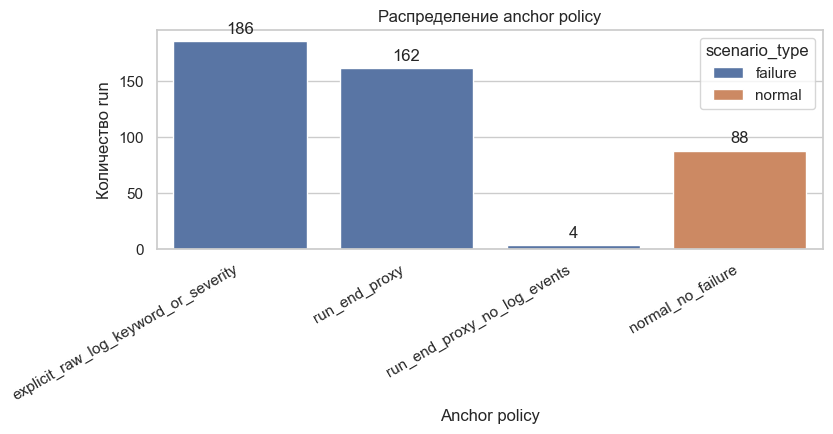

In [68]:
anchor_policy_plot_df = (
    included_runs_df
    .groupby(["scenario_type", "anchor_policy"], as_index=False)
    .agg(runs=("run_id", "nunique"))
)

plt.figure(figsize=(8.5, 4.5))

ax = sns.barplot(
    data=anchor_policy_plot_df,
    x="anchor_policy",
    y="runs",
    hue="scenario_type",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Распределение anchor policy")
plt.xlabel("Anchor policy")
plt.ylabel("Количество run")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Примеры explicit anchors

In [69]:
explicit_anchor_examples_df = (
    included_runs_df
    .loc[
        included_runs_df["anchor_policy"].eq("explicit_raw_log_keyword_or_severity"),
        [
            "workload",
            "scenario",
            "run_duration_sec",
            "event_anchor",
            "anchor_candidate_count",
            "anchor_message_sample",
        ],
    ]
    .head(8)
    .reset_index(drop=True)
)

display(explicit_anchor_examples_df)

,workload,scenario,run_duration_sec,event_anchor,anchor_candidate_count,anchor_message_sample
0,aggregation,2nd_namenode_killed,99.0,2021-10-20 12:24:25+00:00,3,Driver terminated or disconnected! Shutting down. master3:38091
1,aggregation,datanode_killed,157.0,2021-10-20 12:16:13+00:00,9,I/O error constructing remote block reader.
2,aggregation,master_killed,179.0,2021-10-20 13:01:15+00:00,3,Driver terminated or disconnected! Shutting down. master3:34477
3,aggregation,net_killed,147.0,2021-10-20 12:34:51+00:00,3,Driver terminated or disconnected! Shutting down. master3:40789
4,aggregation,nodemanager_killed,98.0,2021-10-20 12:14:14+00:00,3,Driver terminated or disconnected! Shutting down. master3:38599
5,aggregation,resourcemanager_suspended,257.0,2021-10-20 13:02:53+00:00,2,Exception encountered while connecting to the server : java.net.SocketTimeoutException: 60000 millis timeout while waiting for channel t...
6,aggregation,vm_stress,189.0,2021-10-20 12:44:46+00:00,3,Exception encountered while connecting to the server : java.net.SocketTimeoutException: 60000 millis timeout while waiting for channel t...
7,aggregation,worker_killed,101.0,2021-10-20 12:12:26+00:00,3,Driver terminated or disconnected! Shutting down. master3:39837


### Выводы по разделу

Анализ применимости окон показывает, что `10s` сохраняет достаточную временную детализацию: медианный запуск разбивается на 12 окон, а общее число окон остаётся вычислительно приемлемым. При увеличении окна до `30s` медианное число окон снижается до 4, поэтому этот размер можно использовать как дополнительную проверку устойчивости. Окно `60s` подходит скорее для macro-context, а `5min` не является пригодной primary target-сеткой, поскольку большая часть запусков схлопывается в одно окно.

Политика anchor строится консервативно. Для failure-сценариев сначала ищется explicit anchor в raw log: событие с высоким уровнем логирования или сообщением, содержащим ключевые слова, связанные с типом сценария. Чтобы не принять startup noise за отказ, ранние события в начале run отсекаются. Если устойчивый explicit anchor не найден, используется `run_end_proxy`. Такой proxy сохраняется в отдельной колонке `anchor_policy` и не трактуется как истинный момент отказа.

Для normal-сценариев anchor не задаётся, а target-разметка остаётся нулевой. Для failure-сценариев вокруг anchor формируются два горизонта: короткий risk horizon и более широкий warning horizon. Их длина адаптируется к длительности run, чтобы короткие запуски не получали непропорционально длинную область риска.

Таким образом, основной baseline contract строится на `micro=10s` и `macro=60s`, а качество target-разметки контролируется через явную переменную `anchor_policy`. Это позволяет отличать случаи с явным raw-log маркером отказа от случаев, где используется приближённый `run_end_proxy`.

## 6. Multi-rate сетка и выравнивание log/KPI

На этом этапе формируется оконная структура baseline-датасета.  
Для каждого `run_id` строится micro-сетка с шагом `10s`, а логовые признаки считаются в двух масштабах:

- micro-window: `[window_ts, window_end)`;
- macro-context: trailing-интервал `[window_end - macro_window, window_end)`.

Целевые переменные рассчитываются относительно `window_end`.  
Объединение признаков выполняется только по ключу `run_id + window_index`, чтобы не смешивать данные разных запусков.

### Построение окон и targets

In [70]:
def build_window_grid(included_runs: pd.DataFrame, micro_sec: int):
    rows = []
    capped_rows = []

    for record in included_runs.itertuples(index=False):
        duration = float(record.run_duration_sec)
        n_windows = int(max(1, math.ceil(duration / micro_sec)))

        if n_windows > MAX_WINDOWS_PER_RUN_SAFETY:
            capped_rows.append(
                {
                    "run_id": record.run_id,
                    "original_windows": n_windows,
                    "used_windows": MAX_WINDOWS_PER_RUN_SAFETY,
                }
            )
            n_windows = MAX_WINDOWS_PER_RUN_SAFETY

        for window_index in range(n_windows):
            window_ts = record.run_start + pd.Timedelta(
                seconds=window_index * micro_sec
            )
            window_end = window_ts + pd.Timedelta(seconds=micro_sec)

            rows.append(
                {
                    "workload": record.workload,
                    "scenario": record.scenario,
                    "run_id": record.run_id,

                    "group_id": getattr(record, "group_id", record.run_id),

                    "failure_family": record.failure_family,
                    "scenario_type": record.scenario_type,
                    "window_index": window_index,
                    "window_ts": window_ts,
                    "window_end": window_end,
                    "run_start": record.run_start,
                    "run_end": record.run_end,
                    "fail_start": record.fail_start,
                    "event_anchor": record.event_anchor,
                    "anchor_policy": record.anchor_policy,
                    "risk_horizon_sec": record.risk_horizon_sec,
                    "warning_horizon_sec": record.warning_horizon_sec,
                    "target_available": bool(record.target_available),
                    "target_policy": record.target_policy,
                    "micro_window_sec": micro_sec,
                    "macro_window_sec": MACRO_WINDOW_SEC,
                    "parsed_label_available": int(bool(record.parsed_label_available)),
                    "strict_path_pair": int(bool(record.strict_path_pair)),
                }
            )

    return pd.DataFrame(rows), pd.DataFrame(capped_rows)

def label_dual_targets(windows: pd.DataFrame):
    df = windows.copy()

    df["minutes_before_fail"] = np.nan
    df["y_warning"] = 0
    df["y_risk"] = 0
    df["y_anomaly"] = 0

    failure_mask = df["scenario_type"].eq("failure") & df["event_anchor"].notna()

    seconds_to_anchor = (
        df.loc[failure_mask, "event_anchor"]
        - df.loc[failure_mask, "window_end"]
    ).dt.total_seconds()

    contains_anchor = (
        (df.loc[failure_mask, "window_ts"] <= df.loc[failure_mask, "event_anchor"])
        & (df.loc[failure_mask, "event_anchor"] < df.loc[failure_mask, "window_end"])
    )

    effective_seconds = seconds_to_anchor.clip(lower=0)
    df.loc[failure_mask, "minutes_before_fail"] = effective_seconds / 60

    warning_horizon = df.loc[failure_mask, "warning_horizon_sec"].astype(float)
    risk_horizon = df.loc[failure_mask, "risk_horizon_sec"].astype(float)

    warning_positive = (
        ((seconds_to_anchor >= 0) & (seconds_to_anchor <= warning_horizon))
        | contains_anchor
    )

    risk_positive = (
        ((seconds_to_anchor >= 0) & (seconds_to_anchor <= risk_horizon))
        | contains_anchor
    )

    df.loc[failure_mask, "y_warning"] = warning_positive.astype(int).values
    df.loc[failure_mask, "y_risk"] = risk_positive.astype(int).values
    df.loc[failure_mask, "y_anomaly"] = (
        warning_positive | risk_positive
    ).astype(int).values

    df["state"] = "normal"
    df.loc[df["scenario_type"].eq("failure"), "state"] = "failure_background"
    df.loc[df["y_warning"].eq(1), "state"] = "warning"
    df.loc[df["y_risk"].eq(1), "state"] = "risk"

    return df

### Агрегация log-признаков

In [71]:
def aggregate_log_features(
    windows: pd.DataFrame,
    events: pd.DataFrame,
    macro_sec: int,
    micro_sec: int,
):
    feature_columns = [
        "macro_log_count",
        "macro_unique_components",
        "macro_warn_count",
        "macro_error_count",
        "macro_keyword_count",
        "macro_log_rate",
        "micro_log_count",
        "micro_unique_components",
        "micro_warn_count",
        "micro_error_count",
        "micro_keyword_count",
        "micro_log_rate",
        "micro_error_rate",
    ]

    if events.empty:
        base = windows[["run_id", "window_index"]].copy()

        for column in feature_columns:
            base[column] = 0

        base["log_text"] = ""
        base["log_available"] = 0

        return base

    events_by_run = {
        run_id: group.sort_values("timestamp").reset_index(drop=True)
        for run_id, group in events.groupby("run_id")
    }

    rows = []

    def count_level(frame, levels):
        if frame is None or frame.empty:
            return 0
        return int(frame["level"].isin(levels).sum())

    def unique_components(frame):
        if frame is None or frame.empty:
            return 0
        return int(frame["component"].nunique())

    def keyword_count(frame):
        if frame is None or frame.empty:
            return 0
        return int(frame["keyword_count"].sum())

    for run_id, window_group in windows.groupby("run_id", sort=False):
        run_events = events_by_run.get(run_id)

        for row in window_group.itertuples(index=False):
            window_start = row.window_ts
            window_end = row.window_end
            macro_start = window_end - pd.Timedelta(seconds=macro_sec)

            if run_events is None or run_events.empty:
                micro_events = None
                macro_events = None
            else:
                timestamps = run_events["timestamp"]

                micro_events = run_events[
                    (timestamps >= window_start)
                    & (timestamps < window_end)
                ]

                macro_events = run_events[
                    (timestamps >= macro_start)
                    & (timestamps < window_end)
                ]

            macro_count = 0 if macro_events is None else int(len(macro_events))
            micro_count = 0 if micro_events is None else int(len(micro_events))

            log_text = ""

            if macro_count:
                log_text = (
                    " ".join(macro_events["message_norm"].astype(str).tail(80))
                    [:MAX_LOG_TEXT_CHARS]
                )

            micro_error_count = count_level(micro_events, ["ERROR", "FATAL"])

            rows.append(
                {
                    "run_id": run_id,
                    "window_index": row.window_index,
                    "macro_log_count": macro_count,
                    "macro_unique_components": unique_components(macro_events),
                    "macro_warn_count": count_level(macro_events, ["WARN"]),
                    "macro_error_count": count_level(macro_events, ["ERROR", "FATAL"]),
                    "macro_keyword_count": keyword_count(macro_events),
                    "macro_log_rate": macro_count / macro_sec,
                    "micro_log_count": micro_count,
                    "micro_unique_components": unique_components(micro_events),
                    "micro_warn_count": count_level(micro_events, ["WARN"]),
                    "micro_error_count": micro_error_count,
                    "micro_keyword_count": keyword_count(micro_events),
                    "micro_log_rate": micro_count / micro_sec,
                    "micro_error_rate": (
                        micro_error_count / micro_count
                        if micro_count
                        else 0.0
                    ),
                    "log_text": log_text,
                    "log_available": int(macro_count > 0),
                }
            )

    return pd.DataFrame(rows)

### Сборка оконного log-dataset

In [72]:
window_grid_df, capped_windows_df = build_window_grid(
    included_runs_df,
    MICRO_WINDOW_SEC,
)

window_labeled_df = label_dual_targets(window_grid_df)

log_window_features_df = aggregate_log_features(
    window_labeled_df,
    raw_events_df,
    MACRO_WINDOW_SEC,
    MICRO_WINDOW_SEC,
)

window_labeled_df = window_labeled_df.merge(
    log_window_features_df,
    on=["run_id", "window_index"],
    how="left",
)

log_feature_cols = [
    column
    for column in window_labeled_df.columns
    if column.startswith("macro_") or column.startswith("micro_")
]

window_labeled_df[log_feature_cols] = window_labeled_df[log_feature_cols].fillna(0)

window_labeled_df["log_text"] = window_labeled_df["log_text"].fillna("")
window_labeled_df["log_available"] = (
    window_labeled_df["log_available"]
    .fillna(0)
    .astype(int)
)

### Короткая сводка

In [73]:
window_summary_df = pd.DataFrame(
    [
        {
            "included_runs": window_labeled_df["run_id"].nunique(),
            "windows": len(window_labeled_df),
            "micro_window_sec": MICRO_WINDOW_SEC,
            "macro_window_sec": MACRO_WINDOW_SEC,
            "capped_runs": len(capped_windows_df),
            "warning_positive": int(window_labeled_df["y_warning"].sum()),
            "risk_positive": int(window_labeled_df["y_risk"].sum()),
            "warning_prevalence": window_labeled_df["y_warning"].mean(),
            "risk_prevalence": window_labeled_df["y_risk"].mean(),
        }
    ]
)

window_summary_df

,included_runs,windows,micro_window_sec,macro_window_sec,capped_runs,warning_positive,risk_positive,warning_prevalence,risk_prevalence
0,440,10237,10,60,0,2997,1255,0.292762,0.122595


### Диагностические графики

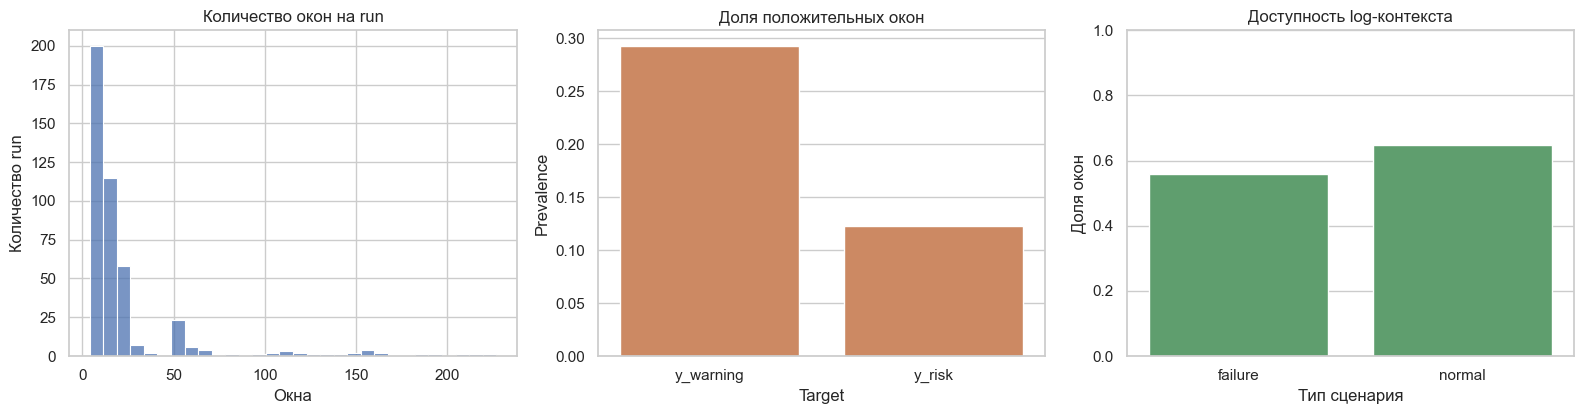

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

per_run_windows = window_labeled_df.groupby("run_id").size()

sns.histplot(
    per_run_windows,
    bins=30,
    ax=axes[0],
    color="#4C72B0",
)

axes[0].set_title("Количество окон на run")
axes[0].set_xlabel("Окна")
axes[0].set_ylabel("Количество run")


target_prevalence_df = pd.DataFrame(
    {
        "target": ["y_warning", "y_risk"],
        "prevalence": [
            window_labeled_df["y_warning"].mean(),
            window_labeled_df["y_risk"].mean(),
        ],
    }
)

sns.barplot(
    data=target_prevalence_df,
    x="target",
    y="prevalence",
    ax=axes[1],
    color="#DD8452",
)

axes[1].set_title("Доля положительных окон")
axes[1].set_xlabel("Target")
axes[1].set_ylabel("Prevalence")


log_coverage_df = (
    window_labeled_df
    .groupby("scenario_type", as_index=False)
    .agg(log_available=("log_available", "mean"))
)

sns.barplot(
    data=log_coverage_df,
    x="scenario_type",
    y="log_available",
    ax=axes[2],
    color="#55A868",
)

axes[2].set_title("Доступность log-контекста")
axes[2].set_xlabel("Тип сценария")
axes[2].set_ylabel("Доля окон")
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### Выводы по разделу

Построенная multi-rate сетка включает **440 run** и **10 237 окон** при основном micro-шаге `10s` и macro-контексте `60s`. Ограничение `MAX_WINDOWS_PER_RUN_SAFETY` не сработало ни для одного запуска, поэтому все окна были сформированы без принудительного обрезания.

Распределение числа окон на run показывает, что большинство запусков имеют умеренное количество окон, однако присутствует правый хвост из более длинных запусков. Это подтверждает, что оконное представление сохраняет различия в длительности run и не сводит каждый запуск к одной агрегированной строке.

Целевые переменные не являются вырожденными: `y_warning` содержит **2 997** положительных окон, а `y_risk` — **1 255** положительных окон. Доля положительных окон составляет примерно **29.3%** для `y_warning` и **12.3%** для `y_risk`. Это ожидаемо: warning-horizon шире risk-horizon, поэтому он захватывает больше окон перед anchor-событием.

Доступность логового контекста различается между типами сценариев. Для normal-сценариев доля окон с доступным macro-log контекстом выше, чем для failure-сценариев. Поэтому `log_available` следует сохранять как диагностический признак покрытия, но использовать его осторожно, чтобы модель не опиралась на сам факт доступности логов как shortcut.

Таким образом, выбранная схема `micro=10s` и `macro=60s` формирует пригодный window-level baseline dataset: число окон вычислительно приемлемо, оба target имеют положительные и отрицательные классы, а log/KPI выравниваются по ключу `run_id + window_index` без смешивания разных запусков.

## 7. Сборка итогового baseline contract

На этом этапе оконная сетка из раздела 6 объединяется с KPI-признаками.  
Парсер KPI и compact-схема уже определены в разделе 4, поэтому здесь выполняется только применение этой схемы к included runs и сборка итогового `contract_df`.

KPI values не сохраняются как отдельная long-table. Каждый instrument-файл читается, агрегируется в micro-window и сразу присоединяется к оконному датасету по ключу `run_id + window_index`.

### Агрегация KPI values в окна

In [75]:
from collections import defaultdict
from tqdm.auto import tqdm

run_window_counts = (
    window_labeled_df
    .groupby("run_id")["window_index"]
    .max()
    .add(1)
    .to_dict()
)

run_start_epoch = {
    row.run_id: row.run_start.timestamp()
    for row in included_runs_df.itertuples(index=False)
}

selected_kpi_files_df = (
    kpi_meta_df
    .loc[
        kpi_meta_df["run_id"].isin(set(included_runs_df["run_id"]))
        & kpi_meta_df["expected_metric"]
        & kpi_meta_df["metric"].isin(KPI_SELECTED_COLUMNS)
        & kpi_meta_df["first_dt"].notna()
    ]
    .copy()
)

run_feature_frames = defaultdict(list)
recency_frames = []
kpi_value_issues = []
kpi_schema_rows = []

for record in tqdm(
    selected_kpi_files_df.itertuples(index=False),
    total=len(selected_kpi_files_df),
    desc="KPI value aggregation",
):
    if record.run_id not in run_start_epoch:
        continue

    if record.run_id not in run_window_counts:
        continue

    try:
        feature_frame, recency_frame, issue_or_schema = kpi_feature_frame_for_file(
            record,
            run_start_epoch[record.run_id],
            int(run_window_counts[record.run_id]),
            MICRO_WINDOW_SEC,
        )

        if isinstance(issue_or_schema, dict):
            kpi_value_issues.append(issue_or_schema)

        elif isinstance(issue_or_schema, list):
            kpi_schema_rows.extend(issue_or_schema)

        if feature_frame is not None and not feature_frame.empty:
            run_feature_frames[record.run_id].append(
                feature_frame.set_index("window_index")
            )

        if recency_frame is not None and not recency_frame.empty:
            recency_frame = recency_frame.copy()
            recency_frame["run_id"] = record.run_id
            recency_frames.append(recency_frame)

    except Exception as exc:
        kpi_value_issues.append(
            {
                "run_id": record.run_id,
                "host": record.host,
                "metric": record.metric,
                "path": str(record.path),
                "issue": f"unexpected exception: {exc}",
            }
        )

KPI value aggregation:   0%|          | 0/15840 [00:00<?, ?it/s]

In [76]:
kpi_selection_check_df = pd.DataFrame(
    [
        {
            "all_kpi_files": len(kpi_meta_df),
            "included_run_files": int(
                kpi_meta_df["run_id"].isin(set(included_runs_df["run_id"])).sum()
            ),
            "expected_metric_files": int(kpi_meta_df["expected_metric"].sum()),
            "selected_metric_files": int(
                kpi_meta_df["metric"].isin(KPI_SELECTED_COLUMNS.keys()).sum()
            ),
            "selected_kpi_files": len(selected_kpi_files_df),
            "selected_runs": selected_kpi_files_df["run_id"].nunique(),
            "selected_metrics": selected_kpi_files_df["metric"].nunique(),
        }
    ]
)

display(kpi_selection_check_df)

,all_kpi_files,included_run_files,expected_metric_files,selected_metric_files,selected_kpi_files,selected_runs,selected_metrics
0,16093,15841,16092,16092,15840,440,6


In [77]:
included_run_ids = set(included_runs_df["run_id"])

kpi_selection_debug_df = pd.DataFrame(
    [
        {
            "step": "all kpi_meta_df rows",
            "rows": len(kpi_meta_df),
        },
        {
            "step": "expected metrics",
            "rows": int(kpi_meta_df["expected_metric"].sum()),
        },
        {
            "step": "selected metric names",
            "rows": int(kpi_meta_df["metric"].isin(KPI_SELECTED_COLUMNS).sum()),
        },
        {
            "step": "included run_id",
            "rows": int(kpi_meta_df["run_id"].isin(included_run_ids).sum()),
        },
        {
            "step": "first_dt notna",
            "rows": int(kpi_meta_df["first_dt"].notna().sum()),
        },
        {
            "step": "final selected_kpi_files_df",
            "rows": len(selected_kpi_files_df),
        },
    ]
)

display(kpi_selection_debug_df)

,step,rows
0,all kpi_meta_df rows,16093
1,expected metrics,16092
2,selected metric names,16092
3,included run_id,15841
4,first_dt notna,16092
5,final selected_kpi_files_df,15840


### Сборка KPI feature frame

In [78]:
kpi_run_parts = []

for run_id, frames in run_feature_frames.items():
    if not frames:
        continue

    merged = pd.concat(frames, axis=1)

    if merged.columns.duplicated().any():
        merged = merged.T.groupby(level=0).first().T

    merged.index.name = "window_index"
    merged = merged.reset_index()
    merged["run_id"] = run_id

    kpi_run_parts.append(merged)

kpi_window_features_df = (
    pd.concat(kpi_run_parts, ignore_index=True)
    if kpi_run_parts
    else pd.DataFrame(columns=["run_id", "window_index"])
)

kpi_value_issues_df = pd.DataFrame(kpi_value_issues)

kpi_feature_schema_df = (
    pd.DataFrame(kpi_schema_rows)
    .drop_duplicates(subset=["feature_base"])
    .reset_index(drop=True)
    if kpi_schema_rows
    else pd.DataFrame()
)

if recency_frames:
    kpi_recency_df = (
        pd.concat(recency_frames, ignore_index=True)
        .groupby(["run_id", "window_index"], as_index=False)["last_kpi_ts_epoch"]
        .max()
    )
else:
    kpi_recency_df = pd.DataFrame(
        columns=[
            "run_id",
            "window_index",
            "last_kpi_ts_epoch",
        ]
    )

### Cборка `contract_df`

In [79]:
contract_df = window_labeled_df.merge(
    kpi_window_features_df,
    on=["run_id", "window_index"],
    how="left",
)

contract_df = contract_df.merge(
    kpi_recency_df,
    on=["run_id", "window_index"],
    how="left",
)

kpi_value_cols = [
    column
    for column in contract_df.columns
    if column.startswith("kpi_") and "__" in column
]

kpi_mean_cols = [
    column
    for column in kpi_value_cols
    if column.endswith("__mean")
]

contract_df["kpi_feature_count"] = (
    contract_df[kpi_value_cols].notna().sum(axis=1)
    if kpi_value_cols
    else 0
)

contract_df["kpi_series_available"] = (
    contract_df[kpi_mean_cols].notna().sum(axis=1)
    if kpi_mean_cols
    else 0
)

total_series_bases = max(1, len(kpi_mean_cols))

contract_df["kpi_avail_ratio"] = (
    contract_df["kpi_series_available"] / total_series_bases
)

contract_df["kpi_available"] = (
    contract_df["kpi_series_available"] > 0
).astype(int)

contract_df["kpi_recency_sec"] = np.nan

has_last_kpi_ts = contract_df["last_kpi_ts_epoch"].notna()

contract_df.loc[has_last_kpi_ts, "kpi_recency_sec"] = (
    contract_df.loc[has_last_kpi_ts, "window_end"].map(lambda x: x.timestamp())
    - contract_df.loc[has_last_kpi_ts, "last_kpi_ts_epoch"]
)

contract_df.loc[
    contract_df["kpi_recency_sec"] < 0,
    "kpi_recency_sec",
] = 0

contract_df["has_both_modalities"] = (
    (contract_df["log_available"] == 1)
    & (contract_df["kpi_available"] == 1)
).astype(int)

contract_df["hard_negative"] = (
    (contract_df["y_warning"] == 0)
    & (contract_df["y_risk"] == 0)
    & (
        (contract_df["log_available"] == 1)
        | (contract_df["kpi_available"] == 1)
    )
).astype(int)

### Порядок обязательных колонок

In [80]:
required_front_cols = [
    "workload",
    "scenario",
    "run_id",
    "group_id",
    "failure_family",
    "scenario_type",
    "window_ts",
    "window_end",
    "run_start",
    "run_end",
    "fail_start",
    "event_anchor",
    "anchor_policy",
    "minutes_before_fail",
    "macro_window_sec",
    "micro_window_sec",
    "state",
    "y_warning",
    "y_risk",
    "y_anomaly",
    "target_available",
    "target_policy",
    "log_text",
    "log_available",
    "macro_log_count",
    "macro_unique_components",
    "macro_warn_count",
    "macro_error_count",
    "macro_keyword_count",
    "macro_log_rate",
    "micro_log_count",
    "micro_unique_components",
    "micro_warn_count",
    "micro_error_count",
    "micro_keyword_count",
    "micro_log_rate",
    "micro_error_rate",
    "kpi_available",
    "kpi_series_available",
    "kpi_feature_count",
    "kpi_avail_ratio",
    "kpi_recency_sec",
    "has_both_modalities",
    "hard_negative",
    "parsed_label_available",
    "strict_path_pair",
]

required_front_cols = [
    column
    for column in required_front_cols
    if column in contract_df.columns
]

other_cols = [
    column
    for column in contract_df.columns
    if column not in required_front_cols
    and column != "last_kpi_ts_epoch"
]

contract_df = contract_df[required_front_cols + other_cols]

### Короткий отчёт

In [81]:
coverage_report_df = pd.DataFrame(
    {
        "metric": [
            "rows",
            "runs",
            "kpi_feature_columns",
            "kpi_feature_bases",
            "kpi_parse_issues",
            "mean_kpi_avail_ratio",
            "kpi_available_share",
            "has_both_modalities_share",
        ],
        "value": [
            len(contract_df),
            contract_df["run_id"].nunique(),
            len(kpi_value_cols),
            len(kpi_mean_cols),
            len(kpi_value_issues_df),
            float(contract_df["kpi_avail_ratio"].mean()),
            float(contract_df["kpi_available"].mean()),
            float(contract_df["has_both_modalities"].mean()),
        ],
    }
)

display(coverage_report_df)

if not kpi_value_issues_df.empty:
    display(kpi_value_issues_df.head(15))

,metric,value
0,rows,10237.000000
1,runs,440.000000
2,kpi_feature_columns,2160.000000
3,kpi_feature_bases,432.000000
4,kpi_parse_issues,0.000000
5,mean_kpi_avail_ratio,0.985005
6,kpi_available_share,0.999609
7,has_both_modalities_share,0.567940


In [82]:
diagnostic_df = pd.DataFrame(
    [
        {
            "rows": len(contract_df),
            "runs": contract_df["run_id"].nunique(),
            "kpi_feature_columns": len(
                [
                    col
                    for col in contract_df.columns
                    if col.startswith("kpi_") and "__" in col
                ]
            ),
            "kpi_window_feature_rows": len(kpi_window_features_df),
            "kpi_available_share": contract_df["kpi_available"].mean(),
            "mean_kpi_avail_ratio": contract_df["kpi_avail_ratio"].mean(),
            "has_both_modalities_share": contract_df["has_both_modalities"].mean(),
            "log_available_share": contract_df["log_available"].mean(),
        }
    ]
)

display(diagnostic_df)

,rows,runs,kpi_feature_columns,kpi_window_feature_rows,kpi_available_share,mean_kpi_avail_ratio,has_both_modalities_share,log_available_share
0,10237,440,2160,10233,0.999609,0.985005,0.56794,0.568135


### Графики покрытия KPI и обеих модальностей

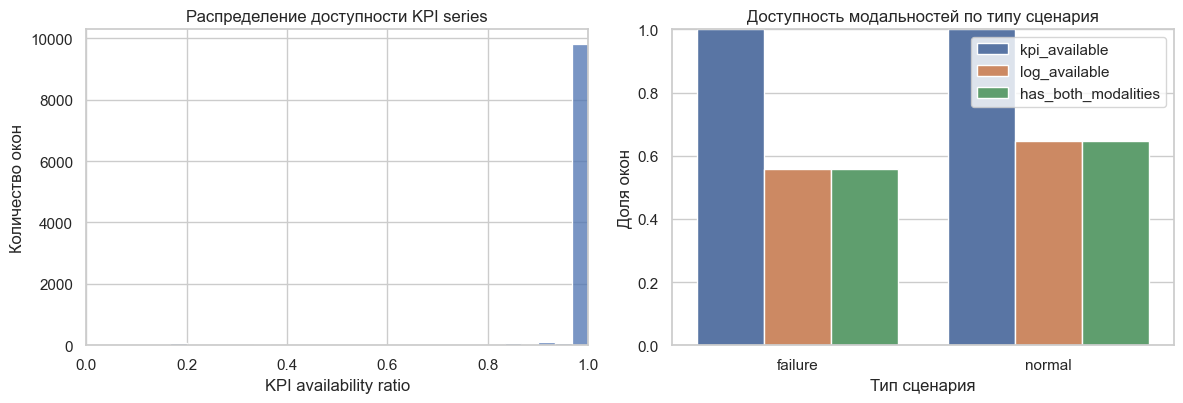

In [86]:
plot_df = contract_df.copy()

both_modalities_df = (
    plot_df
    .groupby("scenario_type", as_index=False)
    .agg(
        kpi_available=("kpi_available", "mean"),
        log_available=("log_available", "mean"),
        has_both_modalities=("has_both_modalities", "mean"),
    )
)

coverage_plot_df = both_modalities_df.melt(
    id_vars="scenario_type",
    value_vars=[
        "kpi_available",
        "log_available",
        "has_both_modalities",
    ],
    var_name="coverage_type",
    value_name="share",
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.histplot(
    plot_df["kpi_avail_ratio"].dropna(),
    bins=30,
    ax=axes[0],
    color="#4C72B0",
)

axes[0].set_title("Распределение доступности KPI series")
axes[0].set_xlabel("KPI availability ratio")
axes[0].set_ylabel("Количество окон")
axes[0].set_xlim(0, 1)


sns.barplot(
    data=coverage_plot_df,
    x="scenario_type",
    y="share",
    hue="coverage_type",
    ax=axes[1],
)

axes[1].set_title("Доступность модальностей по типу сценария")
axes[1].set_xlabel("Тип сценария")
axes[1].set_ylabel("Доля окон")
axes[1].set_ylim(0, 1)
axes[1].legend(title="")

plt.tight_layout()
plt.show()

### Выводы по разделу

На данном этапе KPI values были агрегированы в ту же `10s` оконную сетку, что и логовые признаки и target-разметка. Итоговый contract содержит **10 237 окон** для **440 run**. Для KPI-модальности сформировано **2 160 признаковых столбцов**, соответствующих **432 базовым KPI series** до применения оконных статистик.

Парсер KPI отработал без ошибок на выбранной compact-схеме: число `kpi_parse_issues` равно **0**. Это подтверждает, что предварительно выбранный набор KPI-колонок пригоден для автоматической агрегации по окнам.

Средняя доля доступных KPI series на окно составляет **0.985**, а доля окон с хотя бы одним KPI-признаком — около **0.9996**. Следовательно, KPI-модальность почти полностью покрывает сформированную оконную сетку.

Основная неполнота связана не с KPI, а с совместной доступностью обеих модальностей: `has_both_modalities_share` составляет около **0.568**, поскольку не каждое окно содержит log-контекст в соответствующем macro-интервале.

Missing values в KPI-признаках не заменяются нулями на этапе сборки contract. Отсутствие значения и нулевое значение имеют разный смысл, поэтому пропуски должны обрабатываться внутри model pipeline, например через imputer. Признаки покрытия `kpi_available`, `log_available`, `has_both_modalities` и `kpi_avail_ratio` сохраняются как диагностические переменные.

Таким образом, `contract_df` объединяет временные окна, log features, KPI features, target-разметку и признаки покрытия в единую таблицу. Этот объект является основным baseline-датасетом для последующего train/test split и smoke-baseline моделей.

## 8. Валидация контракта и anti-leakage split

На этом этапе проверяется, что итоговый `contract_df` можно использовать для smoke-baseline обучения.

Проверяются три аспекта:

- корректность ключей и обязательных столбцов;
- наличие обоих классов target после разбиения;
- отсутствие leakage-признаков в будущей feature matrix.

Основная стратегия разбиения — holdout по workload. Если такое разбиение не сохраняет оба класса в train/test, используется fallback-разбиение по `run_id`.

### Правила валидации и leakage columns

In [88]:
REQUIRED_CONTRACT_COLUMNS = required_front_cols.copy()

LEAKAGE_COLUMNS = {
    "workload",
    "scenario",
    "run_id",
    "group_id",
    "failure_family",
    "scenario_type",
    "window_index",
    "window_ts",
    "window_end",
    "run_start",
    "run_end",
    "fail_start",
    "event_anchor",
    "anchor_policy",
    "anchor_candidate_count",
    "anchor_message_sample",
    "minutes_before_fail",
    "risk_horizon_sec",
    "warning_horizon_sec",
    "state",
    "target_available",
    "target_policy",
    "split_group",
    "split",
    "y_warning",
    "y_risk",
    "y_anomaly",
}


def validate_contract(df: pd.DataFrame):
    rows = []

    duplicate_count = int(
        df.duplicated(["run_id", "window_ts", "micro_window_sec"]).sum()
    )

    rows.append(
        {
            "check": "duplicate_key_count",
            "column": "run_id + window_ts + micro_window_sec",
            "value": duplicate_count,
            "status": "pass" if duplicate_count == 0 else "fail",
        }
    )

    for column in REQUIRED_CONTRACT_COLUMNS:
        present = column in df.columns
        null_share = float(df[column].isna().mean()) if present else np.nan

        rows.append(
            {
                "check": "required_column",
                "column": column,
                "value": null_share,
                "status": "pass" if present else "fail",
            }
        )

    for target in ["y_warning", "y_risk", "y_anomaly"]:
        if target in df.columns:
            values = sorted(df[target].dropna().unique().tolist())
            valid = set(values).issubset({0, 1})
        else:
            values = []
            valid = False

        rows.append(
            {
                "check": "binary_target",
                "column": target,
                "value": json.dumps(values),
                "status": "pass" if valid else "fail",
            }
        )

    feature_cols = [
        column
        for column in df.columns
        if (
            (column.startswith("kpi_") and "__" in column)
            or column.startswith("macro_")
            or column.startswith("micro_")
        )
    ]

    empty_feature_columns = (
        int(df[feature_cols].isna().all(axis=0).sum())
        if feature_cols
        else 0
    )

    rows.extend(
        [
            {
                "check": "all_empty_feature_columns",
                "column": "feature_columns",
                "value": empty_feature_columns,
                "status": "pass" if empty_feature_columns == 0 else "warn",
            },
            {
                "check": "artifact_row_count",
                "column": "contract",
                "value": len(df),
                "status": "info",
            },
            {
                "check": "target_prevalence",
                "column": "y_warning",
                "value": float(df["y_warning"].mean()),
                "status": "info",
            },
            {
                "check": "target_prevalence",
                "column": "y_risk",
                "value": float(df["y_risk"].mean()),
                "status": "info",
            },
            {
                "check": "coverage_prevalence",
                "column": "kpi_available",
                "value": float(df["kpi_available"].mean()),
                "status": "info",
            },
            {
                "check": "coverage_prevalence",
                "column": "has_both_modalities",
                "value": float(df["has_both_modalities"].mean()),
                "status": "info",
            },
            {
                "check": "feature_group_count",
                "column": "kpi_series_aware",
                "value": len(
                    [
                        column
                        for column in df.columns
                        if column.startswith("kpi_") and "__" in column
                    ]
                ),
                "status": "info",
            },
            {
                "check": "feature_group_count",
                "column": "log_numeric",
                "value": len(
                    [
                        column
                        for column in df.columns
                        if column.startswith("macro_")
                        or column.startswith("micro_")
                    ]
                ),
                "status": "info",
            },
        ]
    )

    return pd.DataFrame(rows)

### Group-aware split

In [89]:
def make_group_aware_split(df: pd.DataFrame):
    workloads = sorted(df["workload"].unique())

    test_workloads = set(workloads[::4])

    split = np.where(
        df["workload"].isin(test_workloads),
        "test",
        "train",
    )

    tmp = df.assign(split=split)

    train_has_both_classes = tmp.loc[tmp["split"] == "train", "y_warning"].nunique() == 2
    test_has_both_classes = tmp.loc[tmp["split"] == "test", "y_warning"].nunique() == 2

    if train_has_both_classes and test_has_both_classes:
        tmp["split_group"] = tmp["workload"]
        return tmp, "holdout_by_workload"

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.25,
        random_state=RANDOM_SEED,
    )

    row_index = np.arange(len(df))

    train_idx, test_idx = next(
        splitter.split(
            row_index,
            df["y_warning"],
            groups=df["run_id"],
        )
    )

    split = np.array(["train"] * len(df), dtype=object)
    split[test_idx] = "test"

    tmp = df.copy()
    tmp["split"] = split
    tmp["split_group"] = tmp["run_id"]

    return tmp, "fallback_group_shuffle_by_run_id"


contract_df, split_strategy = make_group_aware_split(contract_df)
contract_report_df = validate_contract(contract_df)

### Compact validation report

In [90]:
validation_status_df = (
    contract_report_df
    .groupby("status", as_index=False)
    .agg(checks=("check", "count"))
    .sort_values("status")
)

display(validation_status_df)

validation_problems_df = (
    contract_report_df
    .loc[contract_report_df["status"].isin(["fail", "warn"])]
    .reset_index(drop=True)
)

if not validation_problems_df.empty:
    display(validation_problems_df)

,status,checks
0,info,7
1,pass,51


### Split summary и leakage diagnostics

In [91]:
split_summary_df = (
    contract_df
    .groupby("split", as_index=False)
    .agg(
        rows=("run_id", "size"),
        runs=("run_id", "nunique"),
        workloads=("workload", "nunique"),
        warning_prevalence=("y_warning", "mean"),
        risk_prevalence=("y_risk", "mean"),
        kpi_available_share=("kpi_available", "mean"),
        both_modalities_share=("has_both_modalities", "mean"),
    )
)

workload_split_df = (
    contract_df[["split", "workload"]]
    .drop_duplicates()
    .sort_values(["split", "workload"])
)

family_split_df = (
    contract_df
    .groupby(["split", "failure_family"], as_index=False)
    .agg(
        rows=("run_id", "size"),
        runs=("run_id", "nunique"),
    )
)

feature_candidate_cols = [
    column
    for column in contract_df.columns
    if column not in LEAKAGE_COLUMNS
]

leakage_in_features = sorted(
    set(feature_candidate_cols) & LEAKAGE_COLUMNS
)

leakage_summary_df = pd.DataFrame(
    [
        {
            "Показатель": "split strategy",
            "Значение": split_strategy,
        },
        {
            "Показатель": "leakage columns in feature candidates",
            "Значение": len(leakage_in_features),
        },
        {
            "Показатель": "train workloads",
            "Значение": ", ".join(
                sorted(contract_df.loc[contract_df["split"] == "train", "workload"].unique())
            ),
        },
        {
            "Показатель": "test workloads",
            "Значение": ", ".join(
                sorted(contract_df.loc[contract_df["split"] == "test", "workload"].unique())
            ),
        },
    ]
)

display(split_summary_df)
display(leakage_summary_df)

,split,rows,runs,workloads,warning_prevalence,risk_prevalence,kpi_available_share,both_modalities_share
0,test,2567,113,4,0.283600,0.128944,0.999610,0.472926
1,train,7670,327,12,0.295828,0.120469,0.999609,0.599739


,Показатель,Значение
0,split strategy,holdout_by_workload
1,leakage columns in feature candidates,0
2,train workloads,"als, bayes, graph_pagerank, lda, nweight, repartition, scan, sleep, sort, terasort, web_pagerank, wordcount"
3,test workloads,"aggregation, join, rf, svd"


### Графики split

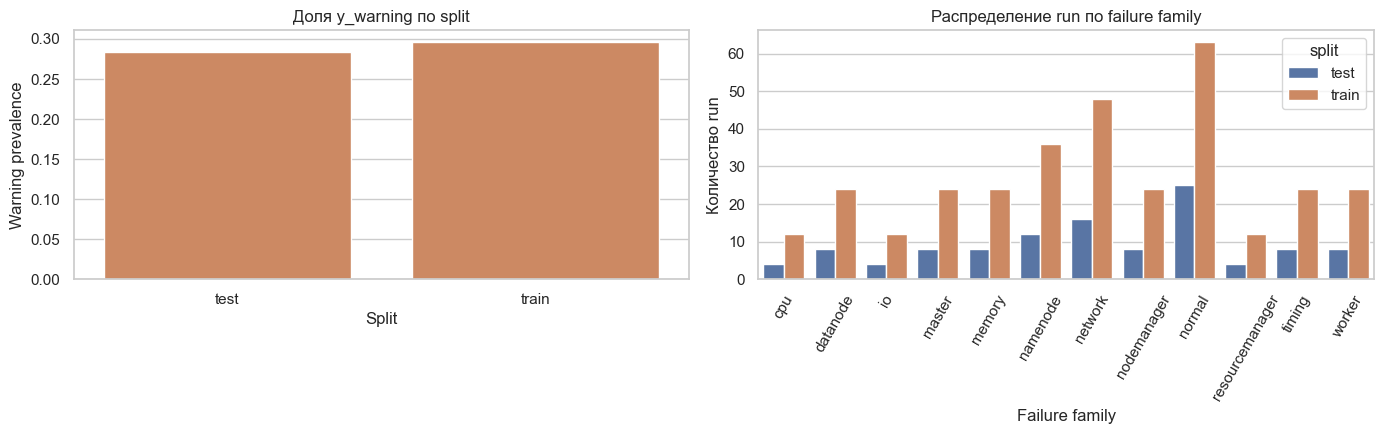

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(
    data=split_summary_df,
    x="split",
    y="warning_prevalence",
    ax=axes[0],
    color="#DD8452",
)

axes[0].set_title("Доля y_warning по split")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Warning prevalence")


sns.barplot(
    data=family_split_df,
    x="failure_family",
    y="runs",
    hue="split",
    ax=axes[1],
)

axes[1].set_title("Распределение run по failure family")
axes[1].set_xlabel("Failure family")
axes[1].set_ylabel("Количество run")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

### Выводы по разделу

Валидация показывает, что итоговый `contract_df` проходит базовые проверки структуры: дубликаты по ключу `run_id + window_ts + micro_window_sec` отсутствуют, обязательные столбцы присутствуют, а целевые переменные имеют бинарный формат.

Для train/test используется стратегия `holdout_by_workload`. Это означает, что один и тот же workload не попадает одновременно в train и test, что снижает риск leakage между близкими сценариями внутри одного workload. В текущем split train содержит **327 run** из **12 workload**, а test — **113 run** из **4 workload**.

Доли положительных окон для `y_warning` близки между train и test: примерно **0.296** в train и **0.284** в test. Это важно, поскольку smoke-baseline модели будут сравниваться на split, где оба класса представлены в обеих частях выборки. Для `y_risk` дисбаланс также остаётся умеренным: примерно **0.120** в train и **0.129** в test.

KPI-модальность почти полностью доступна в обеих частях split, тогда как совместная доступность log и KPI отличается сильнее: `both_modalities_share` выше в train, чем в test. Поэтому признаки покрытия нужно сохранять как диагностические переменные и использовать при интерпретации результатов baseline.

Из feature candidates исключаются идентификаторы, timestamp-поля, target-policy columns и сами target-переменные. Семейства отказов могут пересекаться между train и test, но это не является прямым leakage, так как разбиение проводится по workload. Это ограничение следует учитывать при интерпретации качества: модель проверяется на новых workload, но не на полностью новых типах отказов.

## 9. Baseline-модели для проверки data contract

Главный вопрос блока: работает ли contract как baseline-контур, и не объясняется ли результат только availability shortcut?

Smoke models не являются model zoo. Для каждой цели (`y_warning`, `y_risk`) запускаются четыре минимальные проверки:

- `availability-only` — контроль shortcut;
- `log-only` — вклад логовой модальности;
- `kpi-only` — вклад KPI;
- `fused` — минимальная мультимодальность.

Primary metric: Average Precision / PR-AUC. Accuracy намеренно не используется как главный вывод.


### Feature sets и model pipeline

In [94]:
availability_features = [
    "log_available",
    "kpi_available",
    "has_both_modalities",
    "kpi_avail_ratio",
    "kpi_recency_sec",
    "kpi_series_available",
    "kpi_feature_count",
]

log_numeric_features = [
    "macro_log_count",
    "macro_unique_components",
    "macro_warn_count",
    "macro_error_count",
    "macro_keyword_count",
    "macro_log_rate",
    "micro_log_count",
    "micro_unique_components",
    "micro_warn_count",
    "micro_error_count",
    "micro_keyword_count",
    "micro_log_rate",
    "micro_error_rate",
]

kpi_numeric_features = [
    column
    for column in contract_df.columns
    if column.startswith("kpi_")
    and "__" in column
    and contract_df[column].notna().any()
]

feature_sets = {
    "availability-only": {
        "numeric": availability_features,
        "text": False,
    },
    "log-only": {
        "numeric": log_numeric_features,
        "text": True,
    },
    "kpi-only": {
        "numeric": availability_features + kpi_numeric_features,
        "text": False,
    },
    "fused": {
        "numeric": availability_features + log_numeric_features + kpi_numeric_features,
        "text": True,
    },
}

for spec in feature_sets.values():
    spec["numeric"] = [
        column
        for column in spec["numeric"]
        if column in contract_df.columns and column not in LEAKAGE_COLUMNS
    ]


def make_model_pipeline(numeric_features, use_text):
    transformers = []

    if numeric_features:
        transformers.append(
            (
                "num",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric_features,
            )
        )

    if use_text:
        transformers.append(
            (
                "text",
                TfidfVectorizer(
                    max_features=256,
                    min_df=2,
                    ngram_range=(1, 2),
                ),
                "log_text",
            )
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.3,
    )

    classifier = LogisticRegression(
        max_iter=700,
        class_weight="balanced",
        solver="liblinear",
        random_state=RANDOM_SEED,
    )

    return Pipeline(
        [
            ("features", preprocessor),
            ("clf", classifier),
        ]
    )

### Обучение baseline-модели 

In [96]:
from tqdm.auto import tqdm


def compute_binary_metrics(y_true, score, pred):
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score).astype(float)
    pred = np.asarray(pred).astype(int)

    result = {
        "n": int(len(y_true)),
        "positives": int(y_true.sum()),
        "prevalence": float(y_true.mean()) if len(y_true) else np.nan,
        "average_precision": np.nan,
        "roc_auc": np.nan,
        "precision": np.nan,
        "recall": np.nan,
        "f1": np.nan,
    }

    if len(y_true) == 0:
        return result

    if len(np.unique(y_true)) == 2:
        result["average_precision"] = float(average_precision_score(y_true, score))
        result["roc_auc"] = float(roc_auc_score(y_true, score))

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        pred,
        average="binary",
        zero_division=0,
    )

    result.update(
        {
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1),
        }
    )

    return result


train_df = contract_df.loc[contract_df["split"] == "train"].copy()
test_df = contract_df.loc[contract_df["split"] == "test"].copy()

baseline_rows = []

targets = ["y_warning", "y_risk"]
baseline_tasks = [
    (target, baseline_name, spec)
    for target in targets
    for baseline_name, spec in feature_sets.items()
]

for target in tqdm(targets, desc="Prevalence baselines"):
    y_train = train_df[target].astype(int)
    y_test = test_df[target].astype(int)

    prevalence_score = np.repeat(float(y_train.mean()), len(test_df))
    prevalence_pred = (prevalence_score >= 0.5).astype(int)

    baseline_rows.append(
        {
            "target": target,
            "baseline": "prevalence",
            **compute_binary_metrics(y_test, prevalence_score, prevalence_pred),
            "numeric_features": 0,
            "uses_text": False,
            "status": "ok",
        }
    )


for target, baseline_name, spec in tqdm(
    baseline_tasks,
    desc="Training baseline models",
):
    y_train = train_df[target].astype(int)
    y_test = test_df[target].astype(int)

    if y_train.nunique() < 2 or y_test.nunique() < 2:
        baseline_rows.append(
            {
                "target": target,
                "baseline": baseline_name,
                "n": len(test_df),
                "positives": int(y_test.sum()),
                "prevalence": float(y_test.mean()),
                "status": "skipped_degenerate_split",
            }
        )
        continue

    numeric_features = spec["numeric"]
    use_text = spec["text"]

    try:
        model = make_model_pipeline(numeric_features, use_text)

        model_columns = numeric_features + (["log_text"] if use_text else [])

        X_train = train_df[model_columns].copy()
        X_test = test_df[model_columns].copy()

        model.fit(X_train, y_train)

        score = model.predict_proba(X_test)[:, 1]
        pred = (score >= 0.5).astype(int)

        baseline_rows.append(
            {
                "target": target,
                "baseline": baseline_name,
                **compute_binary_metrics(y_test, score, pred),
                "numeric_features": len(numeric_features),
                "uses_text": use_text,
                "status": "ok",
            }
        )

    except ValueError:
        if use_text:
            model = make_model_pipeline(numeric_features, False)

            X_train = train_df[numeric_features].copy()
            X_test = test_df[numeric_features].copy()

            model.fit(X_train, y_train)

            score = model.predict_proba(X_test)[:, 1]
            pred = (score >= 0.5).astype(int)

            baseline_rows.append(
                {
                    "target": target,
                    "baseline": baseline_name,
                    **compute_binary_metrics(y_test, score, pred),
                    "numeric_features": len(numeric_features),
                    "uses_text": False,
                    "status": "ok_numeric_only_fallback",
                }
            )

        else:
            baseline_rows.append(
                {
                    "target": target,
                    "baseline": baseline_name,
                    "n": len(test_df),
                    "positives": int(y_test.sum()),
                    "prevalence": float(y_test.mean()),
                    "status": "failed",
                }
            )

baseline_metrics_df = pd.DataFrame(baseline_rows)

baseline_metrics_df = baseline_metrics_df.sort_values(
    ["target", "average_precision"],
    ascending=[True, False],
).reset_index(drop=True)

Prevalence baselines:   0%|          | 0/2 [00:00<?, ?it/s]

Training baseline models:   0%|          | 0/8 [00:00<?, ?it/s]

In [97]:
baseline_metrics_view = baseline_metrics_df[
    [
        "target",
        "baseline",
        "n",
        "positives",
        "prevalence",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "status",
    ]
].copy()

baseline_metrics_view

,target,baseline,n,positives,prevalence,average_precision,roc_auc,precision,recall,f1,status
0,y_risk,log-only,2567,331,0.128944,0.431237,0.830904,0.393617,0.670695,0.496089,ok
1,y_risk,fused,2567,331,0.128944,0.267761,0.629163,0.145821,0.722054,0.242640,ok
2,y_risk,availability-only,2567,331,0.128944,0.248013,0.749157,0.240864,0.876133,0.377850,ok
3,y_risk,kpi-only,2567,331,0.128944,0.158820,0.499062,0.124254,0.691843,0.210672,ok
4,y_risk,prevalence,2567,331,0.128944,0.128944,0.500000,0.000000,0.000000,0.000000,ok
5,y_warning,fused,2567,728,0.283600,0.551282,0.768708,0.598630,0.600275,0.599451,ok
6,y_warning,log-only,2567,728,0.283600,0.521915,0.775922,0.558704,0.758242,0.643357,ok
7,y_warning,kpi-only,2567,728,0.283600,0.518798,0.727898,0.574879,0.490385,0.529281,ok
8,y_warning,availability-only,2567,728,0.283600,0.415535,0.698882,0.460133,0.760989,0.573499,ok
9,y_warning,prevalence,2567,728,0.283600,0.283600,0.500000,0.000000,0.000000,0.000000,ok


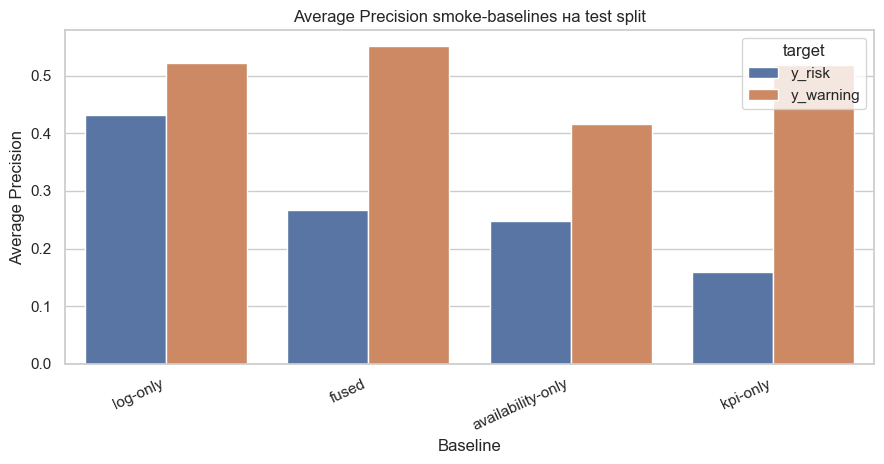

In [98]:
plot_metrics_df = baseline_metrics_df.loc[
    baseline_metrics_df["baseline"].ne("prevalence")
    & baseline_metrics_df["status"].astype(str).str.startswith("ok")
].copy()

plt.figure(figsize=(9, 4.8))

sns.barplot(
    data=plot_metrics_df,
    x="baseline",
    y="average_precision",
    hue="target",
)

plt.title("Average Precision smoke-baselines на test split")
plt.xlabel("Baseline")
plt.ylabel("Average Precision")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Выводы по разделу

Проверочные baseline-модели подтверждают, что baseline-контур собран корректно: модели обучаются на anti-leakage split, feature matrix формируется без идентификаторов, timestamp-полей и target-policy колонок, а обе целевые переменные содержат положительные и отрицательные классы.

Для `y_warning` лучший результат достигается у `fused`-варианта, что подтверждает работоспособность мультимодального объединения log и KPI признаков. При этом `log-only` и `kpi-only` дают близкие значения, поэтому обе модальности содержат полезный сигнал.

Для `y_risk` лучший результат показывает `log-only` baseline. Это согласуется с тем, что короткий risk-horizon сильнее связан с локальными логовыми событиями около anchor, тогда как KPI-признаки отражают более общий системный контекст.

`availability-only` baseline используется как контроль shortcut. Его результат ниже лучших log/fused моделей, значит качество не объясняется только признаками доступности модальностей.

Таким образом, цель раздела выполнена: pipeline обучается без явных утечек, target-переменные не вырождены, а итоговый `contract_df` пригоден для передачи в следующий notebook. Полученные метрики следует рассматривать как проверку корректности data contract, а не как финальное качество модели.

## 10. Сохранение итогового baseline contract

В финале сохраняются только артефакты, необходимые для следующего notebook.

Основной файл — `aligned_multirate_windows.csv`, содержащий window-level dataset с log features, KPI features, target-разметкой, split и diagnostic coverage-признаками.

Дополнительно сохраняется компактный JSON-отчёт `baseline_summary_metrics.json`. Он фиксирует параметры окон, target policy, split strategy, состав feature-групп и результаты проверочных baseline-моделей.

Промежуточные audit-таблицы не сохраняются отдельными CSV, чтобы не перегружать pipeline и не создавать лишние источники состояния.

In [101]:
def sanitize_for_json(obj):
    if isinstance(obj, dict):
        return {str(k): sanitize_for_json(v) for k, v in obj.items()}

    if isinstance(obj, (np.ndarray, list, tuple)):
        return [sanitize_for_json(value) for value in obj]

    if isinstance(obj, pd.Timestamp):
        return obj.isoformat() if pd.notna(obj) else None

    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, (np.floating, float)):
        return float(obj) if np.isfinite(obj) else None

    if isinstance(obj, np.bool_):
        return bool(obj)

    try:
        if pd.isna(obj) and not isinstance(obj, str):
            return None
    except Exception:
        pass

    return obj


aligned_path = OUT_ROOT / "aligned_multirate_windows.csv"
summary_path = OUT_ROOT / "baseline_summary_metrics.json"

# Основной dataset для notebook 03
contract_df.to_csv(aligned_path, index=False)


summary = {
    "contract_path": str(aligned_path.relative_to(PROJECT_ROOT)),
    "rows": int(len(contract_df)),
    "runs": int(contract_df["run_id"].nunique()),
    "workloads": int(contract_df["workload"].nunique()),

    "windows": {
        "micro_window_sec": MICRO_WINDOW_SEC,
        "macro_window_sec": MACRO_WINDOW_SEC,
    },

    "targets": {
        "y_warning_prevalence": float(contract_df["y_warning"].mean()),
        "y_risk_prevalence": float(contract_df["y_risk"].mean()),
        "risk_horizon_sec_base": RISK_HORIZON_SEC,
        "warning_horizon_sec_base": WARNING_HORIZON_SEC,
        "anchor_policy_note": (
            "explicit raw-log keyword/severity else run_end_proxy; "
            "run_end_proxy is not treated as a true fault timestamp"
        ),
    },

    "coverage": {
        "kpi_available_share": float(contract_df["kpi_available"].mean()),
        "log_available_share": float(contract_df["log_available"].mean()),
        "has_both_modalities_share": float(contract_df["has_both_modalities"].mean()),
        "mean_kpi_avail_ratio": float(contract_df["kpi_avail_ratio"].mean()),
    },

    "features": {
        "availability_features": availability_features,
        "log_numeric_features": log_numeric_features,
        "kpi_numeric_feature_count": len(kpi_numeric_features),
        "text_feature": "log_text",
        "excluded_from_predictive_features": sorted(LEAKAGE_COLUMNS),
    },

    "split": {
        "strategy": split_strategy,
        "summary": split_summary_df.to_dict("records"),
    },

    "baseline_metrics": baseline_metrics_df.to_dict("records"),

    "validation": {
        "status_counts": validation_status_df.to_dict("records"),
        "problems": (
            validation_problems_df.to_dict("records")
            if "validation_problems_df" in globals() and not validation_problems_df.empty
            else []
        ),
    },

    "warnings": [
        "Baseline models are used as a data-contract sanity check, not as final quality claims.",
        "Failure anchors may include run_end_proxy and should not be interpreted as true fault timestamps.",
        "Availability-only baseline is a shortcut control.",
        "KPI missing values are not replaced with zero in the contract; imputation is handled in model pipelines.",
    ],
}

with summary_path.open("w", encoding="utf-8") as file:
    json.dump(
        sanitize_for_json(summary),
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

In [100]:
artifact_rows = []

for path in [aligned_path, summary_path]:
    size_bytes = path.stat().st_size if path.exists() else 0

    artifact_rows.append(
        {
            "artifact": str(path.relative_to(PROJECT_ROOT)),
            "exists": path.exists(),
            "size_mb": round(size_bytes / 1024 / 1024, 3),
        }
    )

artifact_report_df = pd.DataFrame(artifact_rows)

display(artifact_report_df)

,artifact,exists,size_mb
0,outputs\raw_multirate\aligned_multirate_windows.csv,True,246.018
1,outputs\raw_multirate\baseline_summary_metrics.json,True,0.007


## Итоговая интерпретация результатов и выводы

В данном notebook сформирован воспроизводимый набор данных для дальнейшего моделирования на основе логов и KPI. Итоговая таблица содержит **10 237 временных окон** для **440 запусков** из **16 workload**. В основной набор включены только те запуски, для которых одновременно доступны raw logs и KPI-измерения; неполные случаи исключены из обучения и используются только как диагностическая информация.

Основная временная сетка выбрана с шагом **10 секунд**, а для логовой модальности дополнительно используется контекст за **60 секунд** до конца окна. Такой формат позволяет учитывать как краткосрочную динамику, так и более широкий предшествующий контекст.

Целевая разметка представлена двумя признаками: `y_warning` и `y_risk`. Они описывают приближение к событию отказа в разных временных горизонтах. При этом часть моментов отказа определяется приближённо через конец запуска, поэтому полученную разметку следует рассматривать как практическую эвристику, а не как точную экспертную аннотацию момента сбоя.

Проверочные модели показали, что собранный набор данных пригоден для обучения: целевые признаки не являются вырожденными, разбиение на обучающую и тестовую части выполняется без прямого пересечения запусков, а логовые и KPI-признаки могут использоваться совместно. Лучший результат для `y_warning` показала объединённая модель с Average Precision около **0.55**, что подтверждает работоспособность контура, но не является финальной оценкой качества.

Следующий этап должен использовать сохранённый файл `outputs/raw_multirate/aligned_multirate_windows.csv` как основной входной набор данных. В notebook `03` следует переходить от проверочных моделей к основной модели, отдельно контролируя влияние доступности модальностей, приближённой целевой разметки и возможного сходства типов отказов между обучающей и тестовой выборками.